# Phase 6 — ระบบรู้จักคำ แต่อ่านประโยคไม่ได้: ทำไม และแก้ยังไง

## เรื่องย่อ (อ่านแค่ตรงนี้ก็พอเข้าใจ)
1. ระบบ**ทายคำเดี่ยวได้ดี** (~90%) แต่**ทายประโยคได้แค่ ~50%**
2. สาเหตุ: เวลาคนทำท่า**ต่อเนื่องไม่หยุด** ส่วนที่ทำหน้าที่หาจุดตัดคำ (**tagger**) มองไม่เห็นว่าคำหนึ่งจบตรงไหน → ตัดคำผิดที่ → ทายผิด
3. ทำไมมองไม่เห็น: tagger ถูกสอนจากคลิปคำเดี่ยวที่ **มีการหยุดนิ่งก่อน-หลังทุกท่า** มันเลยหารอยต่อจาก "การหยุดนิ่ง" — แต่คนทำท่าจริงไม่หยุด
4. แก้: สร้าง**ประโยคปลอมแบบลื่น** (ตัดช่วงหยุดนิ่งทิ้ง) แล้ว**สอน tagger ใหม่** → แยกคำในประโยคต่อเนื่องได้ดีขึ้น และไม่ทำให้อย่างอื่นแย่ลง (ส่วน G)
5. ยังไม่ได้พิสูจน์กับวิดีโอจริง เพราะมีแค่ 5 คลิป

## tagger คืออะไร (ต้องรู้ก่อนอ่านต่อ)
ระบบดูวิดีโอทีละเฟรม (1 วินาที = 25 เฟรม) — **tagger** ตอบทุกเฟรมว่า **"ไม่ได้ทำท่า / เริ่มคำใหม่ / อยู่ในท่าเดิม"** แล้ว**ตัวตัดคำ**ใช้คำตอบนี้หั่นวิดีโอเป็นช่วงๆ ช่วงละ 1 คำ แล้วค่อยส่งแต่ละช่วงไปทายว่าเป็นคำอะไร
ถ้า tagger ไม่บอกว่าคำเริ่มตรงไหน ตัวตัดคำก็ต้องเดา

## ข้อมูลที่พูดถึงในเล่มนี้
| ชื่อ | คืออะไร | ใช้ทำอะไร |
|---|---|---|
| **data_test** | วิดีโอประโยคจริง 5 คลิป (zip จาก Drive) — 3 คลิปทำท่า**ต่อเนื่อง** อีก 2 คลิปมีหยุด | ดูอย่างเดียว ห้ามใช้เลือกค่า (คลิปน้อย) |
| **jack_test** | คลิปตัวอย่างคำ/ตัวอักษร (zip จาก Drive) ไว้ให้คนดูฝึก | ดูว่าทายคำเดี่ยวได้ไหม |
| **TSL51** | ประโยคจริง 252 ประโยค จากคนทดสอบ 1 คน · ส่วนใหญ่อัดแบบไม่เว้นช่วง แต่ทำ**ช้าและค้างมือนิ่ง**ระหว่างคำ | ตัววัดประโยคหลักของโปรเจกต์ (ของเพื่อนใช้ตัวนี้) |
| **ประโยคปลอม / สังเคราะห์** | เอาคลิปคำเดี่ยวมาต่อกันเป็นประโยค | ใช้สอน tagger + ใช้วัดผลแบบทำท่าต่อเนื่อง |

## สารบัญ
| ส่วน | คำถาม |
|---|---|
| A | วิดีโอจาก Drive ได้ผลเท่าไหร่ |
| B | ประโยคพังตรงไหน |
| C | ทำไมไม่เคยเจอปัญหานี้มาก่อน |
| D | แก้ด้วยการปรับตัวเลขง่ายๆ ได้ไหม |
| E | tagger ที่เคยลอง (ข้อ 6) ช่วยไหม |
| F | ทำประโยคปลอมให้เหมือนการทำท่าจริงยังไง |
| **G** | **สอน tagger ใหม่แล้วดีขึ้นไหม ← ผลสุดท้าย** |
| H | ผลอื่นที่ใช้อยู่ (min_frames) + โหมดกล้องสดในเว็บเดโม (มือหาย, fps, กล้องแบบเบา, เกณฑ์ 80%) |
| **I** | **สรุปผลทั้งหมด (ตารางอ่านง่าย) + ขั้นต่อไป** |

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
warnings.filterwarnings('ignore')
plt.rcParams['font.family'] = ['Tahoma', 'Leelawadee UI', 'DejaVu Sans']; plt.rcParams['figure.dpi'] = 110
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 80)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'models' / 'bank.npz').exists())
sys.path.insert(0, str(ROOT / 'pitty' / 'scripts'))
from compare_configs import edits
rd = lambda p: json.loads((ROOT / p).read_text(encoding='utf-8'))
TL = rd('cache/analysis/sentence_timeline.json'); DG = rd('cache/analysis/fluent_diagnostics.json')
FLUENT = ['ฉันปลอบเพื่อนร้องไห้', 'ฉันรักเพื่อน', 'ไปทานข้าวด้วยกันมั้ย']   # the 3 data_test clips signed without pauses

def boot(d, n=10000, seed=0):
    r = np.random.RandomState(seed); bs = [d[r.randint(0, len(d), len(d))].mean() for _ in range(n)]
    return float(d.mean()), float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

**วิธีอ่านตัวอย่างในเล่มนี้** (ใช้ทุกที่ที่เทียบของเดิมกับของใหม่)
- **แถบสี** = นับทีละประโยค: 🟩 ของใหม่ทายคำถูกมากกว่า · ⬜ เท่ากัน · 🟥 ของเดิมทายถูกมากกว่า
- **ตารางตัวอย่าง** = ประโยคจริงเทียบกัน: `คำที่ทำจริง` · ของเดิมได้อะไร · ของใหม่ได้อะไร · **✔ = คำนั้นถูก (อยู่ในเฉลย) · ✗ = ผิด / เกิน** · ใส่ทั้งตัวอย่างที่ดีขึ้นและที่แย่ลง (ไม่เลือกเฉพาะที่ดี)

In [2]:
# helper: compare two runs sentence by sentence (used in D, G, H)
def LJ(path, split=None, style=None):
    rs = json.loads((ROOT / path).read_text(encoding='utf-8'))['results']
    return {r.get('id', r.get('clip')): r for r in rs if (split is None or r['split'] == split) and (style is None or r.get('style') == style)}

def mark(words, ref):
    return ' '.join(w + (' ✔' if w in ref else ' ✗') for w in words) if words else '(ไม่ได้คำเลย)'

def ex_compare(old, new, title, old_name='เดิม (v7)', new_name='ใหม่ (A 25%)', n_good=5, n_bad=3):
    keys = sorted(set(old) & set(new)); rows = []
    for k in keys:
        ref = old[k]['ref']; ho = sum(w in old[k]['top1'] for w in ref); hn = sum(w in new[k]['top1'] for w in ref)
        rows.append({'k': k, 'ref': ref, 'o': old[k]['top1'], 'n': new[k]['top1'], 'd': hn - ho, 'ho': ho, 'hn': hn})
    df = pd.DataFrame(rows)
    b, s, w = int((df.d > 0).sum()), int((df.d == 0).sum()), int((df.d < 0).sum())
    fig, ax = plt.subplots(figsize=(9, 0.9))
    left = 0
    for n, col, lab in ((b, '#2a9d8f', f'ใหม่ทายถูกมากกว่า {b}'), (s, '#c9d1d6', f'เท่ากัน {s}'), (w, '#c8553d', f'เดิมทายถูกมากกว่า {w}')):
        ax.barh([0], [n], left=left, color=col)
        if n: ax.text(left + n / 2, 0, str(n), ha='center', va='center', fontsize=10, fontweight='bold', color='white' if col != '#c9d1d6' else '#1f2a33')
        left += n
    ax.set_xlim(0, len(df)); ax.axis('off'); ax.set_title(f'{title} ({len(df)} ประโยค):  🟩 ใหม่ทายถูกมากกว่า {b}   ⬜ เท่ากัน {s}   🟥 เดิมทายถูกมากกว่า {w}', fontsize=10, loc='left'); plt.show()
    print(f'{title}: ใหม่ทายถูกมากกว่า {b} ประโยค · เท่ากัน {s} · เดิมทายถูกมากกว่า {w}')
    ex = pd.concat([df[df.d > 0].sort_values('d', ascending=False).head(n_good), df[df.d < 0].sort_values('d').head(n_bad)])
    out = pd.DataFrame({'ผล': ex.d.map(lambda x: '✅ ใหม่ดีกว่า' if x > 0 else '❌ เดิมดีกว่า').values,
                        'คำที่ทำจริง (เฉลย)': [' '.join(r) for r in ex.ref],
                        old_name: [mark(o, r) for o, r in zip(ex.o, ex.ref)],
                        new_name: [mark(n, r) for n, r in zip(ex.n, ex.ref)],
                        'ถูก (เดิม → ใหม่)': [f'{a} → {c} จาก {len(r)}' for a, c, r in zip(ex.ho, ex.hn, ex.ref)]})
    display(out)

---
## A. วิดีโอจาก Drive ได้ผลเท่าไหร่

### A1. `data_test` — วิดีโอประโยคจริง 5 คลิป
**ทำยังไง:** เอาวิดีโอเข้าระบบตัวจริง (tagger ของเพื่อน v7, คำศัพท์สนทนา, ไม่ใช้ LLM) แล้วดูว่าได้คำอะไร

**อ่านตาราง:** `เฉลย` = คำที่ทำจริง · `ระบบได้` = คำที่ระบบตัดและทายได้ · `ถูก` = คำในเฉลยที่โผล่ในผล (ไม่สนลำดับ) · `จำนวนคำ` = คำในเฉลย

In [3]:
rows = []
for v, d in TL.items():
    words = [s['word'] for s in d['segments'] if s['status'] != 'transition']
    rows.append({'วิดีโอ': v, 'เฉลย': ' '.join(d['ref']), 'ระบบได้': ' '.join(words), 'ถูก': sum(w in words for w in d['ref']), 'จำนวนคำ': len(d['ref'])})
A1 = pd.DataFrame(rows); display(A1)
print(f"ทายถูกรวม: {A1['ถูก'].sum()} / {A1['จำนวนคำ'].sum()} คำ = {A1['ถูก'].sum() / A1['จำนวนคำ'].sum():.0%}")

,วิดีโอ,เฉลย,ระบบได้,ถูก,จำนวนคำ
0,test1,สวัสดี สบายดี ชอบ โกรธ แมว แฟน ปรบมือ,สวัสดี สบายดี ฉัน ชอบ หก แมว ข้าว แมว,4,7
1,ฉันปลอบเพื่อนร้องไห้,ฉัน ปลอบใจ เพื่อน ร้องไห้,ฉัน เพื่อน ดู สงสาร,2,4
2,ฉันรักเพื่อน,ฉัน รัก เพื่อน,ฉัน รัก,2,3
3,พ่อดื่มน้ำ,พ่อ ดื่ม น้ำ,ศูนย์ พ่อ น้า เกิด ศูนย์,1,3
4,ไปทานข้าวด้วยกันมั้ย,ไป กิน ข้าว ด้วยกัน ไหม,คุณ ฉัน ข้าว ไป,2,5


ทายถูกรวม: 11 / 22 คำ = 50%


**ผลบอกอะไร:** ทายถูกครึ่งเดียว (11 จาก 22 คำ)
- **ลำดับคำ:** เฉลยเขียนแบบภาษาไทย ("พ่อ ดื่ม น้ำ") แต่ท่าจริงเรียงแบบภาษามือ ("พ่อ น้ำ ดื่ม") → เลยนับ "ถูก" แบบไม่สนลำดับ
- **"ไหม"** ไม่ใช่ท่ามือ แต่เป็นสีหน้า (คิ้ว) → ดู B3

### A2. `jack_test` — คลิปคำเดี่ยว
**ข้อควรรู้:** ชุดนี้เป็นคลิปตัวอย่างให้คนฝึกทำท่า **ไม่ใช่ชุดทดสอบ** และคลิปส่วนใหญ่ระบบเคยเห็นตอน train แล้ว → แยกเป็น 2 กลุ่ม

**อ่านตาราง:** `คลิป` = จำนวนคลิป · `ทายถูกอันดับ1` = สัดส่วนที่ทายถูกเป็นคำแรก · `อยู่ใน5อันดับแรก` = คำที่ถูกอยู่ในตัวเลือก 5 อันดับแรก

In [4]:
J = pd.read_csv(ROOT / 'cache/jack_test_results.csv')
J = J[~J.role.str.startswith('letters')]
J['กลุ่ม'] = J.role.map(lambda r: 'เคยเห็นตอน train' if r == 'train' else 'ไม่เคยเห็น')
display(J.groupby('กลุ่ม').agg(**{'คลิป': ('clip', 'size'), 'ทายถูกอันดับ1': ('hit1', 'mean'), 'อยู่ใน5อันดับแรก': ('rank', lambda x: (x.fillna(99) <= 5).mean())}).round(2))
print('คลิปที่ทายผิด:')
display(J[~J.hit1][['word', 'clip', 'top1', 'rank']].rename(columns={'word': 'คำที่ถูก', 'clip': 'คลิป', 'top1': 'ระบบได้', 'rank': 'คำที่ถูกอยู่อันดับ'}))

,คลิป,ทายถูกอันดับ1,อยู่ใน5อันดับแรก
กลุ่ม,,,
เคยเห็นตอน train,24,0.88,0.96
ไม่เคยเห็น,11,0.91,1.00


คลิปที่ทายผิด:


,คำที่ถูก,คลิป,ระบบได้,คำที่ถูกอยู่อันดับ
27,วันนี้,th_sl_S_thsl_00.mp4,ตอนนี้,2.0
30,วันนี้,tsl51_researcher_วันนี้_var_1_0.mp4,ตอนนี้,2.0
31,มา,th_sl_S_thsl_00.mp4,เพื่อน,2.0
40,รู้สึก,th_sl_S_thsl_01.mp4,ขนมปัง,NaN


**ผลบอกอะไร:** คำเดี่ยวทายถูก ~90% แม้กับคลิปที่ไม่เคยเห็น → **ระบบรู้จักคำดีแล้ว** · ที่ผิดเป็นคู่ที่ท่าคล้ายกัน (วันนี้ ↔ ตอนนี้)

### A3. `jack_test` — ตัวอักษร (สะกดนิ้ว J A C K F R)
**ทำยังไง:** ทดสอบ 3 โหมดของระบบ
- `off (ค่าเริ่มต้น)` = ปิดโหมดสะกดนิ้ว — ระบบทายเป็น "คำ" อย่างเดียว
- `auto` = เปิดโหมดสะกดนิ้ว — ระบบเลือกเองว่าตรงไหนเป็นคำ ตรงไหนเป็นตัวอักษร
- `spell_only` = บอกระบบว่ากำลังสะกดอย่างเดียว

**อ่านตารางบน:** `คลิป` = 6 ตัวอักษร × 4 คลิป · `ถูก` = สัดส่วนที่ทายตัวอักษรถูก
**อ่านตารางล่าง:** แต่ละแถว = 1 คลิป · แต่ละคอลัมน์ = ระบบได้อะไรในโหมดนั้น (ถ้าได้คำไทย เช่น "ยาย" = ระบบทายเป็นคำ ไม่ใช่ตัวอักษร)

In [5]:
L = pd.read_csv(ROOT / 'cache/jack_test_letters.csv')
L['clip'] = L['clip'].replace({'en_alpha': 'en_alpha__T04Jsak7vo'})
L['mode'] = L['mode'].replace({'off (default)': 'off (ค่าเริ่มต้น)'})
order = ['off (ค่าเริ่มต้น)', 'auto', 'spell_only']
display(L.groupby('mode').hit.agg(['size', 'mean']).reindex(order).rename(columns={'size': 'คลิป', 'mean': 'ถูก'}).round(2))
display(L.pivot_table(index=['letter', 'clip'], columns='mode', values='output', aggfunc='first')[order].rename_axis(index=['ตัวอักษรที่ถูก', 'คลิป']))

,คลิป,ถูก
mode,,
off (ค่าเริ่มต้น),24,0.00
auto,24,0.88
spell_only,24,0.92


mode                                off (ค่าเริ่มต้น) auto spell_only
ตัวอักษรที่ถูก คลิป                                                  
A              en_alpha_DBQINq0SsAw               ยาย    A          A
               en_alpha__T04Jsak7vo               ยาย    A          A
               en_alpha_gOwZE2kapS8                อา   อา         อา
               en_alpha_tB2ncwN_49k               คุณ    A          A
C              en_alpha_DBQINq0SsAw              ง่วง    C          C
               en_alpha__T04Jsak7vo              ง่วง    C          C
               en_alpha_gOwZE2kapS8              ง่วง    C         CD
               en_alpha_tB2ncwN_49k              ง่วง    C          C
F              en_alpha_DBQINq0SsAw              เก้า    F          F
               en_alpha__T04Jsak7vo              เก้า    F          F
               en_alpha_gOwZE2kapS8              เก้า    F          F
               en_alpha_tB2ncwN_49k              เก้า    F          F
J              en_alpha_DBQINq0SsAw               ยาย    J          J
               en_alpha__T04Jsak7vo               ถูก  ถูก          I
               en_alpha_gOwZE2kapS8               ยาย    J          J
               en_alpha_tB2ncwN_49k             ศูนย์    J          J
K              en_alpha_DBQINq0SsAw               ยาย    K          K
               en_alpha__T04Jsak7vo               ป้า    K          K
               en_alpha_gOwZE2kapS8          ข้าว ลุง   KL         KL
               en_alpha_tB2ncwN_49k               ป้า    K         KT
R              en_alpha_DBQINq0SsAw               ใช้    R          R
               en_alpha__T04Jsak7vo             หนึ่ง    R          R
               en_alpha_gOwZE2kapS8               ใช้    R         RT
               en_alpha_tB2ncwN_49k               ใช้  ใช้          R

**ผลบอกอะไร:** ถ้า**ไม่เปิดโหมดสะกดนิ้ว ได้ 0%** (ระบบพยายามอ่านเป็นคำ เช่น F → "เก้า" เพราะท่าคล้ายเลข 9) · **เปิดแล้วได้ 88–92%** → ถ้าจะสะกดชื่อในเดโม ต้องกดเปิดโหมดนี้ก่อน
(ตัวอักษรเกินท้าย เช่น "CD", "KL" = น่าจะเป็นตอนลดมือ · คลิป `en_alpha` อาจเป็นแหล่งเดียวกับที่ใช้สอนระบบ ผลอาจดีเกินจริง)

---
## B. ประโยคพังตรงไหน

### B1. ระบบ "รู้จัก" คำในประโยคไหม
**ทำยังไง:** ไล่ตัดวิดีโอเป็นช่วงสั้นๆ ทุกตำแหน่ง (เป็นพันช่วงต่อคลิป) แล้วดูว่าคำในเฉลยมี**ช่วงไหนบ้างไหม**ที่ระบบทายเป็นคำนั้นอันดับ 1
**ตัวเทียบ:** ทำแบบเดียวกันกับคำสุ่มที่**ไม่ได้อยู่ในประโยค** — ถ้าคำสุ่มก็เจอบ่อย แปลว่าการไล่หาแบบนี้เจอได้โดยบังเอิญ

**อ่านตาราง:** `มีช่วงที่ได้อันดับ 1` = สัดส่วนคำที่หาเจอ · `จำนวนคำ` = จำนวนคำที่ทดสอบ

In [6]:
cc = DG['chance_control']
display(pd.DataFrame({'คำในประโยค (เฉลย)': [cc['ref_rate'], cc['ref_n']], 'คำสุ่มที่ไม่อยู่ในประโยค': [cc['rnd_rate'], cc['rnd_n']]},
                     index=['มีช่วงที่ได้อันดับ 1', 'จำนวนคำ']).round(2))

,คำในประโยค (เฉลย),คำสุ่มที่ไม่อยู่ในประโยค
มีช่วงที่ได้อันดับ 1,0.86,0.04
จำนวนคำ,21.00,300.00


**ผลบอกอะไร:** คำในประโยค**หาเจอ 86%** แต่คำสุ่มเจอแค่ **4%** → ไม่ใช่บังเอิญ: **ระบบรู้จักคำในประโยคแทบทุกคำ**
แต่ผลจริงทายถูกแค่ 50% (A1) → ที่หายไป ~36% เกิดจาก**ตัดช่วงคำผิดที่** ไม่ใช่เพราะไม่รู้จักคำ

### B2. กราฟ timeline — ดูว่าระบบตัดคำยังไง
**อ่านกราฟ (แกนนอน = วินาที):**
- **กล่องสีด้านบน** = ช่วงที่ระบบตัดเป็น 1 คำ + คำที่ทายได้ (เขียว = มั่นใจ · เหลือง = ไม่แน่ใจ · แดง = ไม่รู้)
- **เส้นน้ำเงิน** = tagger คิดว่า "กำลังทำท่า" แค่ไหน (0–1)
- **เส้นส้ม** = tagger คิดว่า "อยู่ในท่าเดิม" แค่ไหน
- **เส้นจุดเขียว** = tagger คิดว่า "เริ่มคำใหม่" แค่ไหน ← **ตัวที่ใช้หาจุดตัดคำ**
- **แถบเทาด้านล่าง** = ช่วงที่มือยกขึ้น
- **เส้นม่วง** = ช่วงที่คำในเฉลยได้คะแนนสูงสุด (#1 = ได้อันดับ 1 ตรงนั้น)

test1


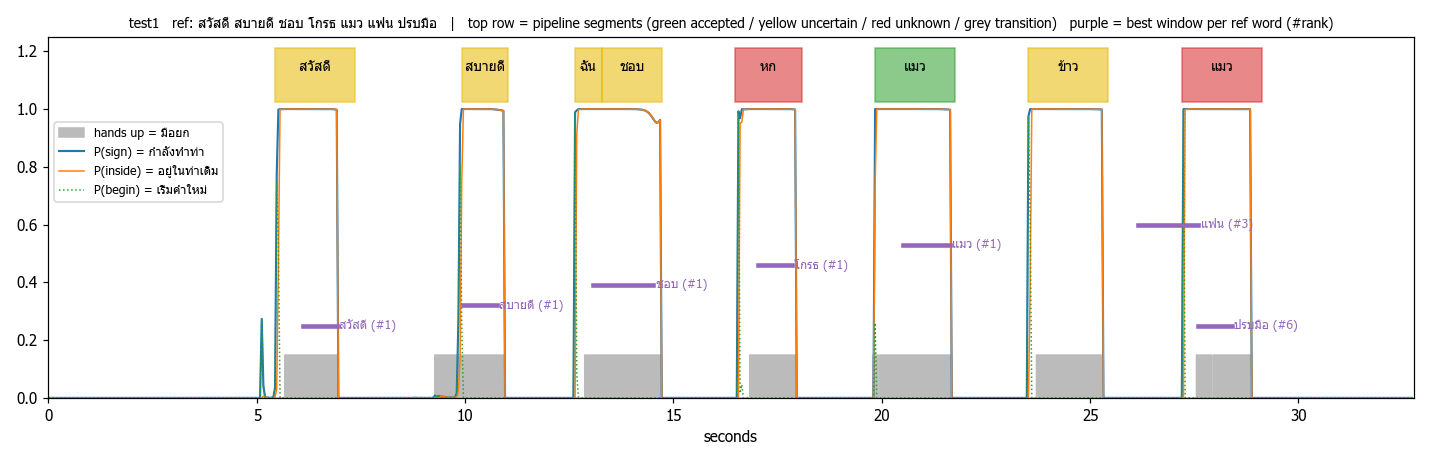

ฉันปลอบเพื่อนร้องไห้


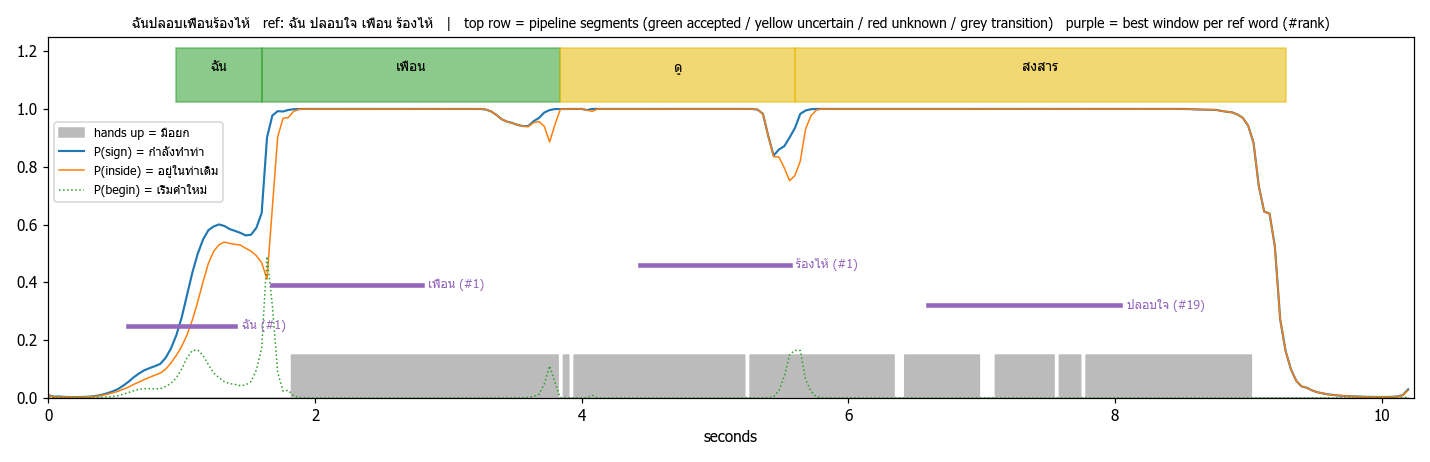

ฉันรักเพื่อน


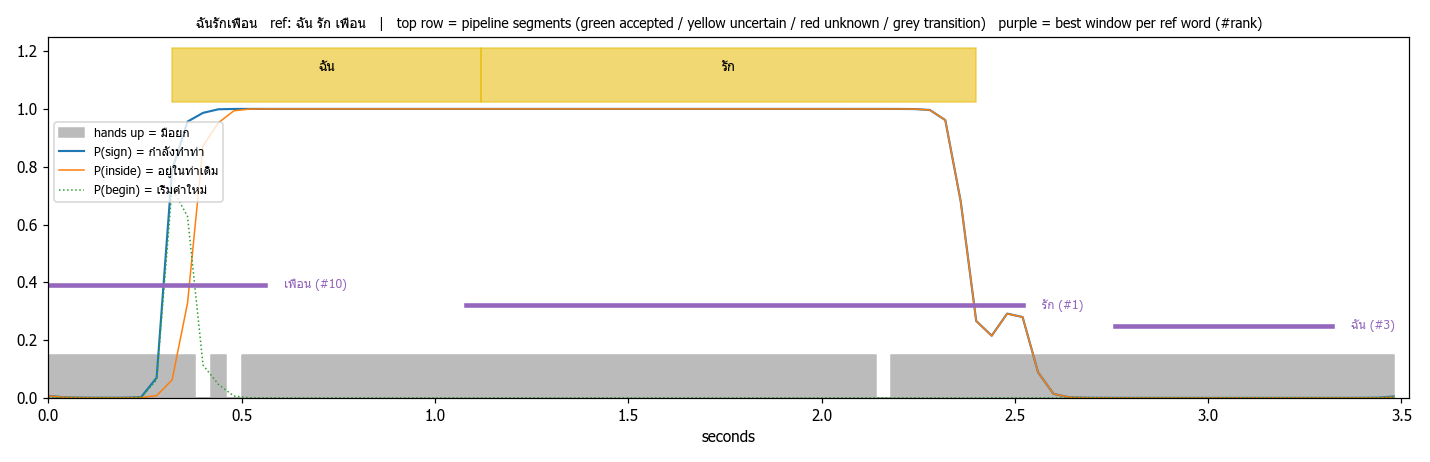

พ่อดื่มน้ำ


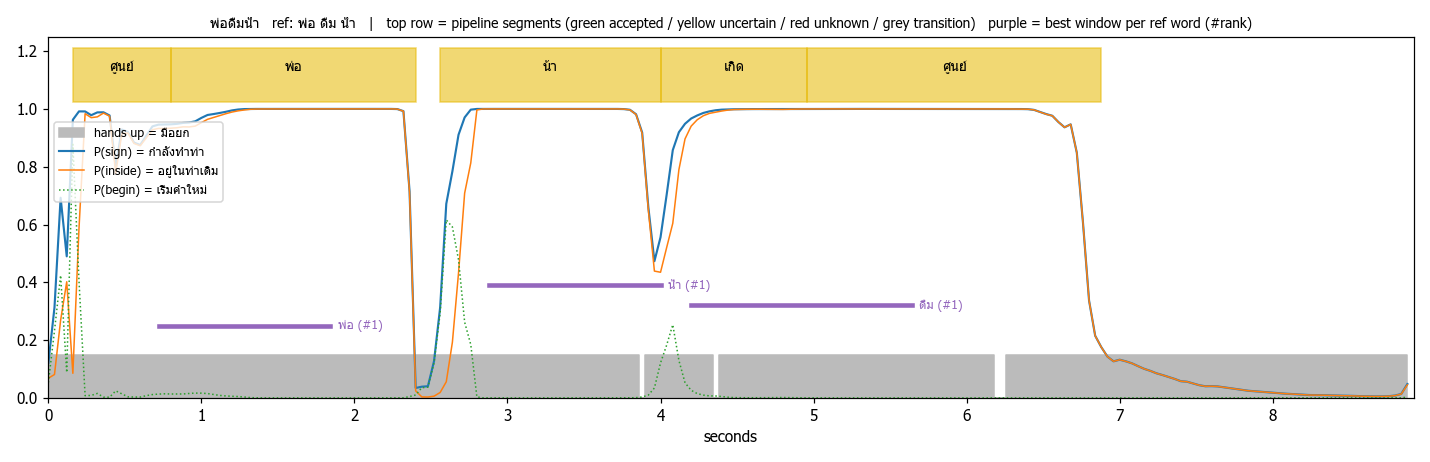

ไปทานข้าวด้วยกันมั้ย


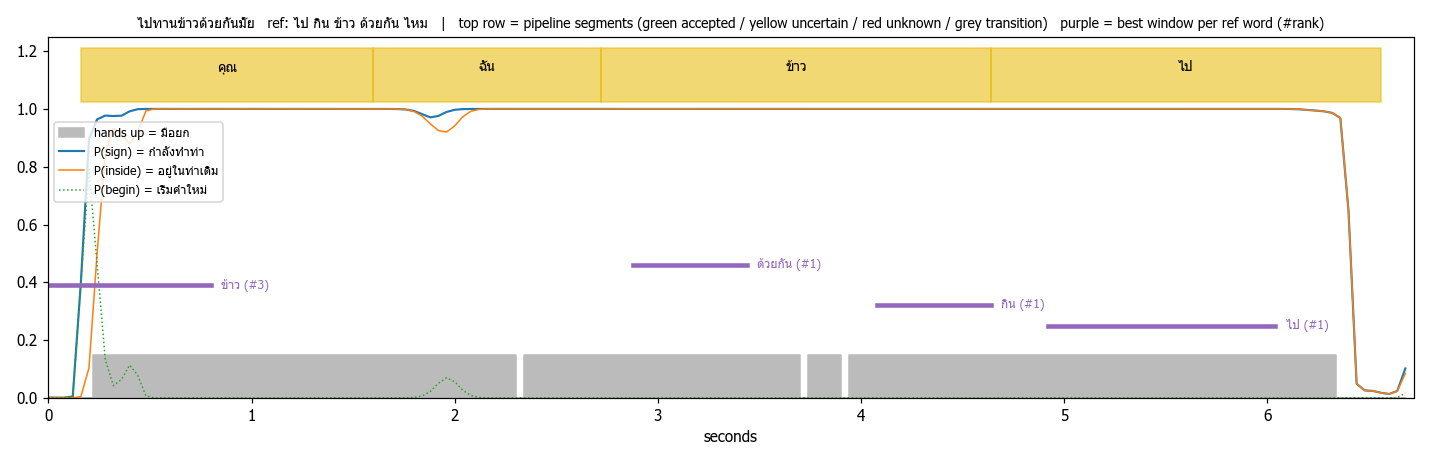

In [7]:
for v in TL:
    print(v); display(Image(filename=str(ROOT / f'cache/analysis/timeline_{v}.png'), width=1000))

**ผลบอกอะไร:**
- คลิปที่ทำท่า**ต่อเนื่อง** (ปลอบ / รักเพื่อน / ไปทานข้าว): เส้นน้ำเงิน**ค้างที่ 1.0 ทั้งประโยค** และเส้นเขียว ("เริ่มคำใหม่") แทบไม่ขึ้น → ระบบต้องเดาจุดตัด
  เช่น ช่วงที่ระบบเรียก "ข้าว" จริงๆ มีท่า "ด้วยกัน" + "กิน" อยู่ข้างใน · ใน "ปลอบเพื่อน" ระบบรู้จัก "ร้องไห้" (เส้นม่วง #1) แต่ตัดช่วงรวมท่าอื่นเข้าไป เลยได้ "ดู"
- **พ่อดื่มน้ำ:** "ดื่ม" ถูกหั่นเป็น "เกิด" + "ศูนย์" · "น้ำ" ตัดเริ่มเร็วไป 0.3 วินาที เลยกลายเป็น "น้า"
- **test1** ทำทีละคำแล้วพัก → เส้นน้ำเงินตกลงระหว่างคำ → tagger เห็นรอยต่อครบ

### B3. คำถาม "ไหม" (ดูจากสีหน้า)
**อ่านตาราง:** `question_yesno_reported` = ระบบบอกว่าเป็นคำถามไหม · `brow_raise_peak` = คิ้วยกสูงสุดแค่ไหน · `brow_raise_tail` = คิ้วยกช่วงท้ายประโยคแค่ไหน · `brow_furrow_rel` = คิ้วขมวดแค่ไหน

In [8]:
display(pd.DataFrame(DG['face']).set_index('video').round(3))

,question_yesno_reported,question_furrow,brow_raise_peak,brow_raise_tail,brow_furrow_rel
video,,,,,
test1,False,False,0.103,0.044,0.004
ฉันปลอบเพื่อนร้องไห้,False,False,0.197,2.815,-0.020
ฉันรักเพื่อน,False,False,0.006,-0.058,0.179
พ่อดื่มน้ำ,False,False,0.385,-0.325,0.027
ไปทานข้าวด้วยกันมั้ย,False,False,0.325,-0.758,-0.013


**ผลบอกอะไร:** ระบบไม่เคยบอกว่าเป็นคำถามเลย เพราะ
- การตรวจคำถามจากสีหน้า**ปิดไว้เป็นค่าเริ่มต้น** (`face_question=False`) และถ้าเปิด ระบบดู "**คิ้วขมวด**" ไม่ใช่ "คิ้วยก"
- คลิปคำถาม ("ไปทานข้าวด้วยกันมั้ย") คิ้วยกสูงสุดในชุด (0.325) แต่ยก**กลางประโยค** ไม่ใช่ท้าย → ถ้าจะใช้ต้องปรับกฎ (มีคลิปคำถามแค่ 1 คลิป ยังทดสอบไม่ได้)



---
## C. ทำไมไม่เคยเจอปัญหานี้มาก่อน

**สรุปสั้นๆ:** ข้อมูลที่ใช้ทั้ง**สอน** tagger และ**สอบ** tagger มาตลอด มี "ช่วงเว้น" ให้เห็นระหว่างคำเสมอ — แต่คนในวิดีโอจริงทำท่าต่อกันโดยไม่เว้น
→ tagger ไม่เคยเจอแบบนี้ตอนเรียน และเราก็ไม่เคยวัดเจอตอนสอบ

**เปรียบเทียบ:** เหมือนสอนเด็กอ่านจากหนังสือที่**เว้นวรรคทุกคำ** แล้วข้อสอบก็เว้นวรรคทุกคำ → เด็กได้คะแนนดี แต่พอให้อ่านข้อความที่**เขียนติดกัน** ก็แยกคำไม่ออก

**ทำไมดู TSL51:** TSL51 คือข้อสอบประโยคชุดหลักที่เพื่อนใช้มาตลอด (ประโยคจริง 252 ประโยค มีเฉลย) — ถ้าข้อสอบนี้ "เว้นวรรค" ให้ทุกคำ ก็ไม่มีทางวัดเจอปัญหานี้

### ดูด้วยตาก่อน
กราฟข้างล่างคือสิ่งที่ tagger (ของเพื่อน) เห็น ในประโยค 2 แบบ · **เส้นน้ำเงิน = tagger คิดว่า "กำลังทำท่า" แค่ไหน** (สูง = ทำท่า · ต่ำ = ไม่ได้ทำ)
- ถ้าเส้น**ตกลงระหว่างคำ** → tagger รู้ว่าตรงนั้นคือรอยต่อ ✔
- ถ้าเส้น**ค้างอยู่ข้างบนตลอด** → tagger ไม่รู้ว่าคำไหนจบตรงไหน ✗

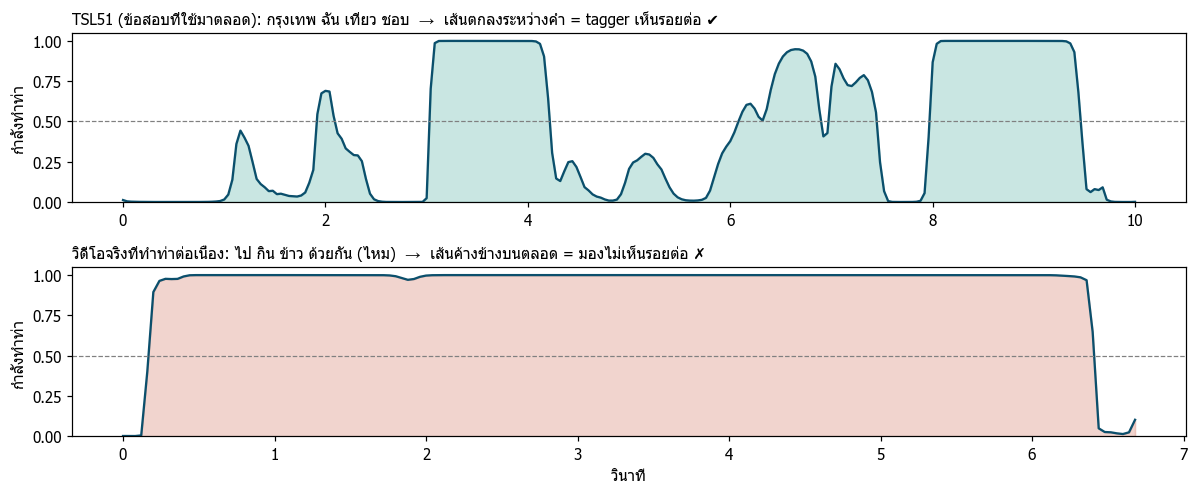

In [9]:
import onnxruntime as ort
sys.path.insert(0, str(ROOT))
import logging; logging.disable(logging.WARNING)
from modules.pipeline import SignPipeline
from modules.encoder import to_iso
from modules.schema import canonical_hands, SH_L, SH_R
from modules.mediapipe_pose import load_raw
_p = SignPipeline(backend='onnx', device='cpu', vocab='conversation', use_llm=False, use_face=False)
_p.be.tagger = ort.InferenceSession(str(ROOT / 'cache/backup_models_v7/tagger.onnx'), providers=['CPUExecutionProvider'])   # tagger ของเพื่อน
AL = rd('artifacts/runs/seq-v7/tsl51_alignment.json')
cid, al = next((c, a) for c, a in AL.items() if c.startswith('t51s:') and a['role'] != 'tagger_train' and a['variation'] == 'no_space' and len(a['glosses']) == 4)
z = np.load(ROOT / 'cloud_s3/data_prep/pose_mp/tsl51_user_sentence' / f"{cid.split(':', 1)[1]}.npz")
kp, sc = z['kp'].astype(np.float32), z['sc'].astype(np.float32); hw = tuple(int(v) for v in z['hw'])
pres = sc[:, [0, SH_L, SH_R]].mean(1) > 0.5; sc[~pres] = 0; kp[~pres] = 0
kp, sc, _ = canonical_hands(kp, sc, hw); prob1, _ = _p._tag(to_iso(kp, hw), sc, pres)
kp2, sc2, hw2, pr2, _ = _p.standardise(load_raw(ROOT / 'cache/data_test_mp/ไปทานข้าวด้วยกันมั้ย.npz')); prob2, _ = _p._tag(to_iso(kp2, hw2), sc2, pr2)
fig, axs = plt.subplots(2, 1, figsize=(11, 4.6))
for ax, prob, ttl, col in ((axs[0], prob1, 'TSL51 (ข้อสอบที่ใช้มาตลอด): ' + ' '.join(al['glosses']) + '  →  เส้นตกลงระหว่างคำ = tagger เห็นรอยต่อ ✔', '#2a9d8f'),
                           (axs[1], prob2, 'วิดีโอจริงที่ทำท่าต่อเนื่อง: ไป กิน ข้าว ด้วยกัน (ไหม)  →  เส้นค้างข้างบนตลอด = มองไม่เห็นรอยต่อ ✗', '#c8553d')):
    t_ = np.arange(len(prob)) / 25; ps = prob[:, 1] + prob[:, 2]
    ax.fill_between(t_, 0, ps, color=col, alpha=0.25); ax.plot(t_, ps, color='#0b4f6c', lw=1.5)
    ax.axhline(0.5, color='grey', ls='--', lw=0.8); ax.set_ylim(0, 1.05); ax.set_ylabel('กำลังทำท่า'); ax.set_title(ttl, fontsize=10, loc='left')
axs[1].set_xlabel('วินาที'); plt.tight_layout(); plt.show()

### แล้วนับเป็นตัวเลข
นับว่าเส้นน้ำเงิน**ขาดออกเป็นกี่ช่วง** (ตกลงต่ำกว่าเส้นประ) แล้วหารด้วยจำนวนคำในประโยค → เรียกว่า **"ช่วงต่อคำ"**

| ประโยค 4 คำ | เส้นขาดเป็น | ช่วงต่อคำ | แปลว่า |
|---|---|---|---|
| ทำทีละคำ มีเว้น | 4 ช่วง | 4 ÷ 4 = **1.0** | tagger เห็นรอยต่อครบทุกคำ ✔ |
| ทำต่อเนื่อง ไม่เว้น | 1 ช่วง | 1 ÷ 4 = **0.25** | tagger มองไม่เห็นรอยต่อเลย ✗ |

**อ่านตาราง:** แต่ละแถว = ข้อมูล 1 กลุ่ม · `ประโยค` = จำนวนประโยคที่ใช้นับ · `ช่วงต่อคำ` = ตามตารางด้านบน · `ประโยคที่เป็นก้อนเดียว` = สัดส่วนประโยคที่ tagger เห็นทั้งประโยคเป็นช่วงเดียว (มองไม่เห็นรอยต่อเลย)

In [10]:
R = pd.DataFrame(DG['runs_per_word'])
summ = lambda d: pd.Series({'ประโยค': len(d), 'ช่วงต่อคำ': d.runs.sum() / d.words.sum(), 'ประโยคที่เป็นก้อนเดียว': (d.runs == 1).mean()})
T = pd.DataFrame({
    'ข้อสอบ TSL51 (ใช้วัดผลมาตลอด)': summ(R[R.source == 'TSL51 tune']),
    'ประโยคปลอมที่ใช้สอน tagger': summ(R[R.source.str.startswith('synthetic')]),
    'วิดีโอจริง ทำทีละคำ/มีเว้น (test1, พ่อดื่มน้ำ)': summ(R[(R.source == 'data_test') & ~R['item'].isin(FLUENT)]),
    'วิดีโอจริง ทำท่าต่อเนื่อง (3 คลิป)': summ(R[(R.source == 'data_test') & R['item'].isin(FLUENT)]),
}).T
display(T.round(2))

,ประโยค,ช่วงต่อคำ,ประโยคที่เป็นก้อนเดียว
ข้อสอบ TSL51 (ใช้วัดผลมาตลอด),126.0,0.97,0.0
ประโยคปลอมที่ใช้สอน tagger,60.0,1.03,0.0
"วิดีโอจริง ทำทีละคำ/มีเว้น (test1, พ่อดื่มน้ำ)",2.0,1.10,0.0
วิดีโอจริง ทำท่าต่อเนื่อง (3 คลิป),3.0,0.25,1.0


**ผลบอกอะไร:**
- **ข้อสอบ TSL51 = 0.97** และ **ประโยคที่ใช้สอน = ~1.0** → ทั้งคู่ "เว้นวรรค" ให้เห็นทุกคำ
- **วิดีโอจริงที่ทำท่าต่อเนื่อง = 0.25** และ**ทุกคลิปเป็นก้อนเดียว** → tagger มองไม่เห็นรอยต่อเลย
- แปลว่า ทั้งตอน**สอน**และตอน**สอบ** ไม่เคยมีคนทำท่าต่อเนื่อง → ปัญหาซ่อนอยู่มาตลอด
- อธิบายด้วยว่าทำไม**ข้อ 6** (รอบก่อน เคยลองสอน tagger แบบทำท่าลื่น แล้วดูเหมือนไม่ได้ผล) — เพราะไปวัดบน TSL51 ซึ่ง "เว้นวรรค" ให้อยู่แล้ว เลยวัดไม่เจอ
- **ทางแก้ (ส่วน F, G):** ทำประโยคที่ใช้สอนให้ "ไม่เว้นวรรค" เหมือนของจริง แล้วสอน tagger ใหม่

### C2. แก้ความเข้าใจ: TSL51 "หยุดพัก" จริงไหม
TSL51 มี 2 แบบ: **`no_space`** (228 ประโยค อัดแบบไม่เว้นช่วง) และ `with_space` (24 ประโยค เว้นช่วง) — ครึ่ง **tune** ถูกใช้สอน tagger แล้ว ส่วนครึ่ง **test** ไม่เคยใช้
**วัดโดยไม่พึ่ง tagger:** `มือนิ่ง+ต่ำ (พัก)` = มือหยุดและลดลง · `มือนิ่ง` = มือหยุด (ทุกระดับความสูง) · `วินาทีต่อคำ` = ความเร็วการทำท่า

In [11]:
T51 = pd.DataFrame([
    ['TSL51 with_space (เว้นช่วง)', '0.92–1.05', 0.26, 0.50, '3.4–3.8'],
    ['TSL51 no_space — tune', 0.98, 0.020, 0.41, 2.52],
    ['TSL51 no_space — test (tagger ไม่เคยเรียน)', 1.07, 0.013, 0.43, 2.39],
    ['data_test ทำท่าต่อเนื่อง', 0.25, 0.018, 0.30, 1.69]],
    columns=['ข้อมูล', 'ท่อนต่อคำ (tagger)', 'มือนิ่ง+ต่ำ (พัก)', 'มือนิ่ง', 'วินาทีต่อคำ']).set_index('ข้อมูล')
display(T51)
HC = ROOT / 'cache/analysis/hold_cut_check.csv'
if HC.exists():
    print('ลองตัดช่วงมือค้างนิ่งระหว่างคำออกจาก TSL51 test no_space (pitty/scripts/hold_cut.py):'); display(pd.read_csv(HC, index_col=0).round(3))

,ท่อนต่อคำ (tagger),มือนิ่ง+ต่ำ (พัก),มือนิ่ง,วินาทีต่อคำ
ข้อมูล,,,,
TSL51 with_space (เว้นช่วง),0.92–1.05,0.260,0.50,3.4–3.8
TSL51 no_space — tune,0.98,0.020,0.41,2.52
TSL51 no_space — test (tagger ไม่เคยเรียน),1.07,0.013,0.43,2.39
data_test ทำท่าต่อเนื่อง,0.25,0.018,0.30,1.69


ลองตัดช่วงมือค้างนิ่งระหว่างคำออกจาก TSL51 test no_space (pitty/scripts/hold_cut.py):


,ท่อนต่อคำ (tagger v7),วินาทีต่อคำ
แบบ,,
ไม่ตัด,1.071,2.390
thr0.10 keep2,0.961,1.816
thr0.15 keep2,0.914,1.594
thr0.20 keep2,0.846,1.430
thr0.15 keep0,0.848,1.423
thr0.20 keep0,0.740,1.258
thr0.25 keep0,0.699,1.138


**ผลบอกอะไร:**
- TSL51 `no_space` **ไม่ได้ลดมือพัก** (มือนิ่ง+ต่ำ 1–2% เท่ากับวิดีโอจริง) — ที่เคยบอกว่า "หยุดพักทุกคำ" จึงไม่ถูก
- แต่คนใน TSL51 ทำท่า**ช้ากว่า** (2.4 vs 1.7 วินาที/คำ) และ**ค้างมือนิ่ง**ระหว่างคำมากกว่า → tagger เห็นรอยต่อ (แม้ในครึ่ง test ที่ไม่เคยเรียน)
- ตัดช่วงค้างออกจนเร็วกว่าคนจริงแล้ว tagger ก็**ยังเห็นรอยต่อ** (~0.70) → ความต่างอยู่ที่**สไตล์การทำท่า**ของแต่ละคนด้วย — ต้องมีวิดีโอคนทำท่าลื่นจริงถึงจะวัดได้ตรง

---
## D. แก้ด้วยการปรับตัวเลขง่ายๆ ได้ไหม

**ไอเดีย:** ไม่ต้องสอน tagger ใหม่ — ปรับค่าตั้งของ**ตัวตัดคำ** แทน
- `lam` = "ค่าปรับต่อ 1 คำ" (สูง = ตัดน้อยคำ คำยาว · ต่ำ = ตัดหลายคำ คำสั้น) ค่าปัจจุบัน = 6
- `beta` = โบนัสถ้า tagger บอกว่าตรงนี้เริ่มคำ

**ทำยังไง (จำลองปัญหา):** ใช้ TSL51 (ส่วน tune) แต่**บังคับเส้น tagger ให้แบน** (มองไม่เห็นรอยต่อ — แบบที่เกิดกับวิดีโอจริง) แล้วลองหลายค่า

**อ่านตารางแรก:** แต่ละแถว = 1 การตั้งค่า (`ปกติ` = tagger ทำงานปกติ · `แบน` = จำลองว่ามองไม่เห็นรอยต่อ) · แต่ละคอลัมน์ = ความเร็วการทำท่า · ตัวเลข = **error รวม (ต่ำ = ดี)**
**อ่านตารางสอง (ความเร็ว 1×):** แยก error เป็น `ทายผิดคำ` / `คำหาย` / `คำเกิน`

In [12]:
def load(name):
    f = ROOT / f'cache/pitty_sent/{name}.json'
    return [r for r in json.loads(f.read_text(encoding='utf-8'))['results'] if r['split'] == 'tune'] if f.exists() else None

def er(rows):
    S = D = I = N = 0
    for r in rows:
        s, d, i = edits(r['ref'], r['top1']); S += s; D += d; I += i; N += len(r['ref'])
    return {'error รวม': (S + D + I) / N, 'ทายผิดคำ': S / N, 'คำหาย': D / N, 'คำเกิน': I / N}

cfgs = {'ปกติ lam6 (ค่าปัจจุบัน)': 'base2', 'ปกติ lam12': 'norm_l12', 'แบน lam6': 'flat_def', 'แบน beta0': 'flat_b0', 'แบน lam3': 'flat_b0l3',
        'แบน lam2': 'flat_b0l2', 'แบน lam8': 'flat_l8', 'แบน lam10': 'flat_l10', 'แบน lam12': 'flat_l12', 'แบน lam14': 'flat_l14', 'แบน lam16': 'flat_l16'}
rows = []
for name, f in cfgs.items():
    for s in ('1.0', '1.5', '2.0'):
        x = load(f'{f}_x{s}')
        if x: rows.append({'การตั้งค่า': name, 'ความเร็ว': s + '×', **er(x)})
D = pd.DataFrame(rows)
display(D.pivot_table(index='การตั้งค่า', columns='ความเร็ว', values='error รวม', sort=False).round(3))
display(D[D['ความเร็ว'] == '1.0×'].set_index('การตั้งค่า')[['error รวม', 'ทายผิดคำ', 'คำหาย', 'คำเกิน']].round(3))

ความเร็ว,1.0×,1.5×,2.0×
การตั้งค่า,,,
ปกติ lam6 (ค่าปัจจุบัน),0.393,0.362,0.384
ปกติ lam12,0.386,0.477,0.501
แบน lam6,0.585,0.472,0.484
แบน beta0,0.590,NaN,NaN
แบน lam3,0.882,NaN,NaN
แบน lam2,1.096,NaN,NaN
แบน lam8,0.525,NaN,NaN
แบน lam10,0.513,NaN,NaN
แบน lam12,0.482,0.523,0.578


,error รวม,ทายผิดคำ,คำหาย,คำเกิน
การตั้งค่า,,,,
ปกติ lam6 (ค่าปัจจุบัน),0.393,0.331,0.043,0.019
ปกติ lam12,0.386,0.309,0.077,0.000
แบน lam6,0.585,0.391,0.022,0.173
แบน beta0,0.590,0.393,0.024,0.173
แบน lam3,0.882,0.388,0.010,0.484
แบน lam2,1.096,0.388,0.005,0.703
แบน lam8,0.525,0.400,0.022,0.103
แบน lam10,0.513,0.400,0.026,0.086
แบน lam12,0.482,0.391,0.036,0.055


**ตารางสาม — ต่างกันจริงไหม:** เทียบ `lam 12` กับค่าปัจจุบัน ทีละประโยค
- `ต่าง` = error เปลี่ยนเท่าไหร่ (ลบ = ดีขึ้น · บวก = แย่ลง)
- `ci_lo` – `ci_hi` = ช่วงความเชื่อมั่น 95% → **ถ้าทั้งสองค่าเป็นลบ = ดีขึ้นจริง · ทั้งสองเป็นบวก = แย่ลงจริง · คร่อม 0 = อาจบังเอิญ**
- `ดีขึ้น` / `แย่ลง` = จำนวนประโยค (จาก 126)

In [13]:
rows = []
for a, b, lab in [('base2', 'norm_l12', 'tagger ปกติ: lam12 เทียบ lam6'), ('flat_def', 'flat_l12', 'tagger แบน: lam12 เทียบ lam6')]:
    for s in ('1.0', '1.5', '2.0'):
        A_, B_ = {r['clip']: r['WER'] for r in load(f'{a}_x{s}')}, {r['clip']: r['WER'] for r in load(f'{b}_x{s}')}
        d = np.array([B_[k] - A_[k] for k in sorted(A_)]); m, lo, hi = boot(d)
        rows.append({'เทียบ': lab, 'ความเร็ว': s + '×', 'ต่าง': m, 'ci_lo': lo, 'ci_hi': hi, 'ดีขึ้น': int((d < 0).sum()), 'แย่ลง': int((d > 0).sum())})
display(pd.DataFrame(rows).round(3))

,เทียบ,ความเร็ว,ต่าง,ci_lo,ci_hi,ดีขึ้น,แย่ลง
0,tagger ปกติ: lam12 เทียบ lam6,1.0×,-0.004,-0.019,0.011,7,4
1,tagger ปกติ: lam12 เทียบ lam6,1.5×,0.117,0.087,0.149,1,43
2,tagger ปกติ: lam12 เทียบ lam6,2.0×,0.118,0.087,0.150,3,45
3,tagger แบน: lam12 เทียบ lam6,1.0×,-0.102,-0.136,-0.068,44,5
4,tagger แบน: lam12 เทียบ lam6,1.5×,0.055,0.026,0.086,9,30
5,tagger แบน: lam12 เทียบ lam6,2.0×,0.092,0.061,0.125,2,34


**ตัวอย่างจริง — ทำไม lam 12 ใช้ไม่ได้** (tagger ทำงานปกติ · TSL51 ครึ่ง tune)
ความเร็วปกติ (1×) เกือบเท่ากัน แต่พอทำท่าเร็ว (2×) lam 12 **ทำคำหาย** (รวมหลายท่าเป็นคำเดียว)

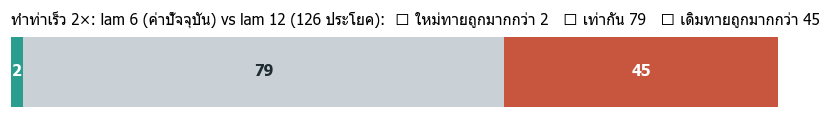

ทำท่าเร็ว 2×: lam 6 (ค่าปัจจุบัน) vs lam 12: ใหม่ทายถูกมากกว่า 2 ประโยค · เท่ากัน 79 · เดิมทายถูกมากกว่า 45


,ผล,คำที่ทำจริง (เฉลย),lam 6 (ปัจจุบัน),lam 12,ถูก (เดิม → ใหม่)
0,✅ ใหม่ดีกว่า,ขอโทษ ฉัน ข้าว กิน ไป,ล้าง ✗ ฉัน ✔ ดู ✗ กลับ ✗,ล้าง ✗ ฉัน ✔ ไป ✔,1 → 2 จาก 5
1,✅ ใหม่ดีกว่า,คุณ เกิด ที่ไหน,ฉัน ✗ ลูก ✗ หนึ่ง ✗,มี ✗ ที่ไหน ✔,0 → 1 จาก 3
2,❌ เดิมดีกว่า,กรุงเทพ น้อง เที่ยว ชอบ,กรุงเทพ ✔ น้อง ✔ หนึ่ง ✗ ชอบ ✔,ชอบ ✔,3 → 1 จาก 4
3,❌ เดิมดีกว่า,ภาษามือ ยาย เรียน ชอบ,ภาษามือ ✔ ย่า ✗ เรียน ✔ ชอบ ✔,ย่า ✗ ชอบ ✔,3 → 1 จาก 4
4,❌ เดิมดีกว่า,ภาษามือ ยาย เรียน ชอบ,ภาษามือ ✔ ย่า ✗ เรียน ✔ ชอบ ✔,ย่า ✗ ชอบ ✔,3 → 1 จาก 4
5,❌ เดิมดีกว่า,ภาษามือ ยาย เรียน ชอบ,ภาษามือ ✔ ย่า ✗ เรียน ✔ ชอบ ✔,ย่า ✗ เรียน ✔,3 → 1 จาก 4
6,❌ เดิมดีกว่า,ขอโทษ ฉัน ข้าว กิน ไป,ขอโทษ ✔ ฉัน ✔ กลับ ✗,ล้าง ✗ กลับ ✗,2 → 0 จาก 5


In [14]:
ex_compare(LJ('cache/pitty_sent/base2_x2.0.json', 'tune'), LJ('cache/pitty_sent/norm_l12_x2.0.json', 'tune'),
           'ทำท่าเร็ว 2×: lam 6 (ค่าปัจจุบัน) vs lam 12', old_name='lam 6 (ปัจจุบัน)', new_name='lam 12', n_good=2, n_bad=5)

**ผลบอกอะไร: ปรับตัวเลขอย่างเดียวแก้ไม่ได้** ❌ (ไม่ได้แก้ไฟล์ไหน)
- พอ tagger มองไม่เห็นรอยต่อ error เพิ่มจาก **0.39 → 0.59** ส่วนใหญ่มาจาก**คำเกิน** (0.02 → 0.17: ท่าเดียวถูกหั่นเป็นหลายคำ) → ยืนยันว่า tagger สำคัญมาก
- `lam 12` ช่วยตอนทำท่าความเร็วปกติ แต่ตอนทำท่า**เร็ว 1.5× / 2× แย่ลงมาก** (คำหายเพิ่ม 3–4 เท่า)
- เพราะค่าที่ดีที่สุด**ขึ้นกับความเร็วที่คนทำท่า** ซึ่งระบบไม่รู้ → ต้องแก้ที่ tagger

---
## E. tagger ที่เคยลอง (ข้อ 6) ช่วยไหม — ⚠️ ใช้ data_test 1 ครั้ง (ได้รับอนุญาต)
**คำถาม:** รอบก่อนเคยสอน tagger แบบ "ทำท่าลื่น" ไว้ (ข้อ 6) — มันมองเห็นรอยต่อในวิดีโอจริงไหม
**ทำยังไง:** นับ "ยอดเริ่มคำใหม่" (เส้นเขียวในกราฟ B2) ในแต่ละคลิป **ดูแค่นี้** ไม่ได้ดูว่าทายคำถูกกี่คำ

**อ่านตาราง:** แถว = คลิป · คอลัมน์ = tagger แต่ละตัว (`v7` = ของเพื่อน · `B_control` = สอนใหม่แบบเดิม (ตัวเทียบ) · `A_coart05` = สอนใหม่แบบทำท่าลื่น) · ตัวเลข = จำนวนจุดเริ่มคำที่ tagger เห็น

In [15]:
TC = pd.DataFrame(DG['tagger_compare'])
fl = TC[TC.video.isin(FLUENT)]
display(TC.pivot_table(index='video', columns='tagger', values='begin_peaks')[['v7', 'B_control', 'A_coart05']].rename_axis(index='วิดีโอ'))
print('3 คลิปที่ทำท่าต่อเนื่อง (รวม 12 คำ) — จุดเริ่มคำที่เห็น:', fl.groupby('tagger').begin_peaks.sum().reindex(['v7', 'B_control', 'A_coart05']).to_dict(), '· ถ้าดีจริงควรได้ ~12')

tagger,v7,B_control,A_coart05
วิดีโอ,,,
test1,6.0,4.0,4.0
ฉันปลอบเพื่อนร้องไห้,1.0,2.0,2.0
ฉันรักเพื่อน,1.0,0.0,1.0
พ่อดื่มน้ำ,2.0,2.0,3.0
ไปทานข้าวด้วยกันมั้ย,1.0,2.0,3.0


3 คลิปที่ทำท่าต่อเนื่อง (รวม 12 คำ) — จุดเริ่มคำที่เห็น: {'v7': 3, 'B_control': 4, 'A_coart05': 6} · ถ้าดีจริงควรได้ ~12


**ผลบอกอะไร:** ตัวที่สอนแบบทำท่าลื่น (A) เห็นจุดเริ่มคำ**มากกว่าเล็กน้อย** (6 vs 4 จาก ~12) → **ทางนี้มีหวัง แต่ยังลื่นไม่พอ** (3 คลิป ส่วนต่างอาจบังเอิญ) → ทำต่อในส่วน F, G

---
## F. ทำประโยคปลอมให้เหมือนการทำท่าจริงยังไง

**ไอเดีย:** tagger เรียนจากประโยคปลอม → ถ้าประโยคปลอม**ไม่มีช่วงหยุดนิ่ง** tagger จะต้องเรียนหารอยต่อจากอย่างอื่น (เหมือนตอนทำท่าจริง)

```
แบบเดิม:  [ยกมือ][หยุด][ ท่า ฉัน ][หยุด][ลดมือ]—[ยกมือ][หยุด][ ท่า รัก ][หยุด]…   ← รอยต่อชัด
แบบลื่น:          [ ท่า ฉัน ]≈≈[ ท่า รัก ]≈≈[ ท่า เพื่อน ]                         ← ตัดหัว-ท้ายท่า + เชื่อมให้กลืน
```

**วัดว่าเหมือนจริงแค่ไหน (ไม่ต้องใช้วิดีโอจริง):** ใช้ tagger ของเพื่อนเป็น "เครื่องตรวจรอยต่อ" นับ `ท่อนต่อคำ` เหมือนส่วน C
→ ยิ่งใกล้ **0.25** (วิดีโอจริงที่ทำท่าต่อเนื่อง) ยิ่งเหมือนจริง · ทดสอบแบบละ 60 ประโยค จากคลิปคนที่ไม่อยู่ใน train

**ชื่อแบบในตาราง:** `trim xx%` = ตัดหัว-ท้ายท่าทิ้ง xx% · `blend` = ให้ท้ายท่าก่อนซ้อนกับต้นท่าถัดไป · `Hermite` = เชื่อมด้วยเส้นโค้งตามความเร็วมือ · `hold` = ตัดช่วงที่มือนิ่ง · `slow join` = เชื่อมช้าลง · `hands` = เติมช่วงมือหาย · `lift` = ไม่ให้มือตกตอนเชื่อม · `high core` = เก็บเฉพาะช่วงที่มือยกสูง · `r2`–`r5` = รอบที่ลอง

**อ่านตาราง:** `sentences` = จำนวนประโยค · `runs_per_word` = **ท่อนต่อคำ (เป้า 0.25)** · `begins_per_word` = จุดเริ่มคำที่เห็นต่อคำ · `single_run` = สัดส่วนประโยคที่เป็นท่อนเดียว

,ประโยค,ท่อนต่อคำ (เป้า 0.25),จุดเริ่มคำต่อคำ,สัดส่วนท่อนเดียว
variant,,,,
plain (เดิม),60.0,1.05,0.99,0.00
core (ตัดยก/ลดมือ),60.0,1.08,0.98,0.00
core+trim10%,60.0,0.90,0.75,0.02
fluent (Hermite),60.0,0.92,0.76,0.02
fluent+blend,60.0,0.90,0.68,0.08
fluent+blend trim20%,60.0,0.61,0.42,0.27
hold0.5+blend,60.0,1.02,0.92,0.02
hold0.5+trim10%+blend,60.0,0.75,0.62,0.15
fluent+blend trim30%,60.0,0.48,0.34,0.40


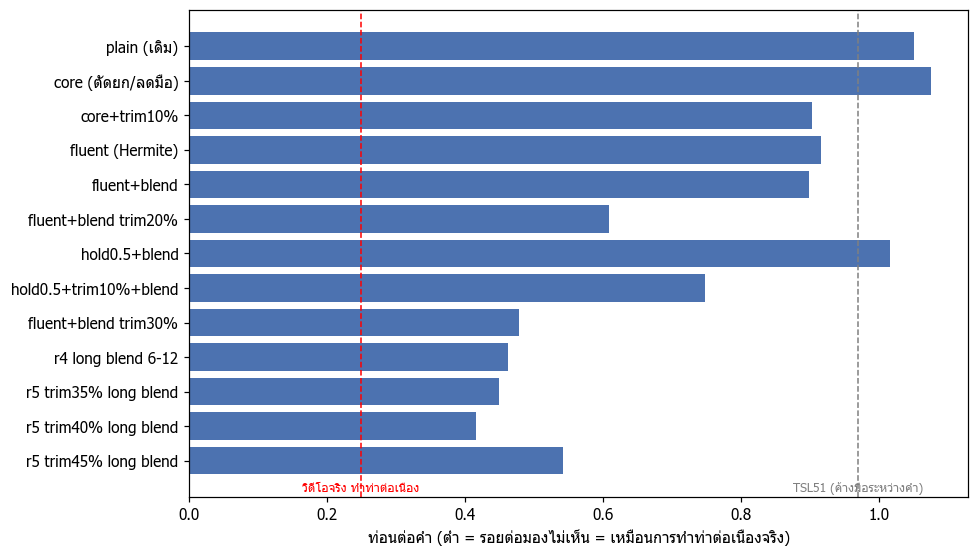

In [16]:
F = pd.read_csv(ROOT / 'cache/analysis/fluent_synth_check.csv', index_col=0)
F0 = pd.read_csv(ROOT / 'cache/analysis/fluent_synth_check_round1b.csv', index_col=0) if (ROOT / 'cache/analysis/fluent_synth_check_round1b.csv').exists() else None
FF = pd.concat([F0, F]) if F0 is not None else F
FF = FF[~FF.index.duplicated(keep='last')]
display(FF.rename(columns={'sentences': 'ประโยค', 'runs_per_word': 'ท่อนต่อคำ (เป้า 0.25)', 'begins_per_word': 'จุดเริ่มคำต่อคำ', 'single_run': 'สัดส่วนท่อนเดียว'}).round(2))
fig, ax = plt.subplots(figsize=(9, 0.32 * len(FF) + 1))
ax.barh(FF.index[::-1], FF.runs_per_word[::-1], color='#4c72b0')
for x, lab, c in [(0.97, 'TSL51 (ค้างมือระหว่างคำ)', 'grey'), (0.25, 'วิดีโอจริง ทำท่าต่อเนื่อง', 'red')]:
    ax.axvline(x, color=c, ls='--', lw=1); ax.text(x, -0.9, lab, color=c, fontsize=8, ha='center')
ax.set_xlabel('ท่อนต่อคำ (ต่ำ = รอยต่อมองไม่เห็น = เหมือนการทำท่าต่อเนื่องจริง)'); plt.tight_layout(); plt.show()

### F2. ตัดหัว-ท้ายท่าแล้ว ท่ายังเป็นท่าเดิมไหม
**ทำยังไง:** เอาคลิปคำเดี่ยว 587 คลิป (คนที่ไม่อยู่ใน train) ตัดหัว-ท้ายแบบต่างๆ แล้วให้ระบบทายคำ
**อ่านตาราง:** `R1` = ทายถูกอันดับ 1 · `R5` = อยู่ใน 5 อันดับแรก · `median_frames` = ความยาวท่าที่เหลือ (เฟรม)

In [17]:
display(pd.read_csv(ROOT / 'cache/analysis/fluent_synth_recog.csv', index_col=0).round(3))

,n,R1,R5,median_frames
cfg,,,,
full span,587,0.734,0.932,46.0
trim10%,587,0.726,0.920,35.0
trim20%,587,0.692,0.908,25.0
trim30%,587,0.620,0.879,17.0
hold0.5,587,0.734,0.932,42.0
hold0.5+trim10%,587,0.717,0.918,34.0


**ผลบอกอะไร:**
- **ตัวที่ทำให้ tagger เห็นรอยต่อคือ "การหยุดนิ่งตอนเริ่ม/จบท่า"** → ตัดหัว-ท้ายทิ้งได้ผลที่สุด (1.05 → 0.42–0.48)
- ลองแก้อย่างอื่นตรงรอยต่อ (เชื่อมช้าลง, ไม่ให้มือตก, ล็อกหัว-ตัว, ผสมรูปมือ) **ไม่ช่วย**
- ยังไม่ถึงเป้า 0.25 · ตัดเยอะไป (45%) แย่ลงอีก
- ตัดหัว-ท้ายแล้ว ท่ายังจำได้ (ตัด 20% เสีย ~4 จุด) — และประโยคปลอมใช้สอน tagger เท่านั้น ไม่ได้ใช้ทายคำ

---
## G. สอน tagger ใหม่แล้วดีขึ้นไหม ← **ผลสุดท้าย**

**ทำยังไง:** สอน tagger ใหม่บน GPU (Modal) หลายตัว — **เหมือนกันทุกอย่าง ต่างแค่ "สัดส่วนประโยคปลอมแบบลื่น"** ที่ใช้สอน

| ชื่อ | ประโยคแบบลื่นตอนสอน | หมายเหตุ |
|---|---|---|
| **v7** | – | ของเพื่อน (ตัวตั้งต้น) |
| **B** | 0% | **ตัวควบคุม** — สอนใหม่แบบเดิมเป๊ะ ไว้เช็กว่าที่ดีขึ้นไม่ได้มาจาก "แค่สอนใหม่" |
| **A 50%** | 50% | ตัดหัว-ท้ายท่า 15–30% |
| **A 25%** | 25% | ตัดหัว-ท้ายท่า 15–30% · **← ตัวที่เลือก ใช้อยู่ใน `models/` ตอนนี้** |
| **v2** | 25% | ตัดหัว-ท้าย 30–40% + ซ้อนรอยต่อยาว (ลื่นกว่า) |

**วัดผล 2 แบบ:**
1. **ประโยคแบบลื่น** (ชุดวัดใหม่) — ประโยคปลอม 240 ประโยค จากคลิปคนที่**ไม่อยู่ใน train** → วัดว่าแยกคำในการทำท่าต่อเนื่องได้ไหม · `same` = สร้างแบบเดียวกับตอนสอน A · `diff` = ตัดเยอะกว่า เร็วกว่า (ยากกว่า)
2. **TSL51** (ทำช้า ค้างมือระหว่างคำ) → กติกา: **ห้ามแย่ลง**

### G0. ดูตัวอย่างจริงก่อน — tagger เดิม (v7) vs ใหม่ (A 25%) · ครึ่ง test

**1) ท่าของคนจริง** (TSL51 ที่ตัดช่วงมือค้างออกให้ลื่นขึ้น · ประโยคจริงเรียงตามไวยากรณ์ภาษามือ)

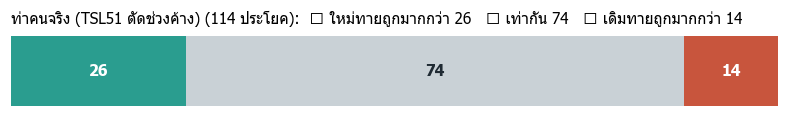

ท่าคนจริง (TSL51 ตัดช่วงค้าง): ใหม่ทายถูกมากกว่า 26 ประโยค · เท่ากัน 74 · เดิมทายถูกมากกว่า 14


,ผล,คำที่ทำจริง (เฉลย),เดิม (v7),ใหม่ (A 25%),ถูก (เดิม → ใหม่)
0,✅ ใหม่ดีกว่า,กรุงเทพ ฉัน เที่ยว ชอบ,ชอบ ✔,กรุงเทพ ✔ ฉัน ✔ ชอบ ✔,1 → 3 จาก 4
1,✅ ใหม่ดีกว่า,ฉัน ชื่อ แมว,ครอบครัว ✗,ฉัน ✔ แมว ✔,0 → 2 จาก 3
2,✅ ใหม่ดีกว่า,กรุงเทพ พี่ เที่ยว ชอบ,พี่ ✔ ที่ไหน ✗,กรุงเทพ ✔ พี่ ✔ ชอบ ✔,1 → 3 จาก 4
3,✅ ใหม่ดีกว่า,แฟน เกิด หูหนวก,ลูก ✗ หูหนวก ✔,แฟน ✔ เกิด ✔ หูหนวก ✔,1 → 3 จาก 3
4,✅ ใหม่ดีกว่า,ฉัน ชื่อ แมว,ไข่ ✗,ฉัน ✔ ชื่อ ✔,0 → 2 จาก 3
5,❌ เดิมดีกว่า,กรุงเทพ พี่ เที่ยว ชอบ,กรุงเทพ ✔ พี่ ✔ เที่ยว ✔,วัด ✗ พี่ ✔ หนึ่ง ✗ ชอบ ✔,3 → 2 จาก 4
6,❌ เดิมดีกว่า,กรุงเทพ แม่ เที่ยว ชอบ,กรุงเทพ ✔ ลุง ✗ เที่ยว ✔ ชอบ ✔,กรุงเทพ ✔ หนึ่ง ✗ ชอบ ✔,3 → 2 จาก 4
7,❌ เดิมดีกว่า,ขนมปัง ฉัน กิน,ขนมปัง ✔ หลาน ✗,หนังสือ ✗ หลาน ✗,1 → 0 จาก 3


In [18]:
ex_compare(LJ('cache/pitty_sent/holdcut_v7_test.json', 'test'), LJ('cache/pitty_sent/holdcut_A25_test.json', 'test'), 'ท่าคนจริง (TSL51 ตัดช่วงค้าง)')

**2) ประโยคแบบลื่น (ชุดยาก diff)** — ประโยคปลอมจากคนนอก train (คำสุ่ม ไม่เรียงตามไวยากรณ์ — ดูที่จำนวนคำที่แยกได้)

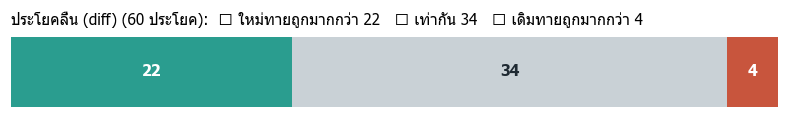

ประโยคลื่น (diff): ใหม่ทายถูกมากกว่า 22 ประโยค · เท่ากัน 34 · เดิมทายถูกมากกว่า 4


,ผล,คำที่ทำจริง (เฉลย),เดิม (v7),ใหม่ (A 25%),ถูก (เดิม → ใหม่)
0,✅ ใหม่ดีกว่า,พ่อ ปู่ ลุง,ป้า ✗,พ่อ ✔ ป้า ✗ ลุง ✔,0 → 2 จาก 3
1,✅ ใหม่ดีกว่า,ลูก สี่ สามี น้องสาว เก้า,ลูก ✔ สามี ✔ น้องสาว ✔,ลูก ✔ สี่ ✔ สามี ✔ น้องสาว ✔ เก้า ✔,3 → 5 จาก 5
2,✅ ใหม่ดีกว่า,หยุด ตา นม โทรศัพท์ ร้องไห้,หยุด ✔ ย่า ✗,หยุด ✔ ตา ✔ งาน ✗ ยาย ✗ ร้องไห้ ✔,1 → 3 จาก 5
3,✅ ใหม่ดีกว่า,ลุง หนึ่ง สี่,ลุง ✔,ลุง ✔ หนึ่ง ✔ สี่ ✔,1 → 3 จาก 3
4,✅ ใหม่ดีกว่า,สี่ สาม ยาย สอง เจ็ด,สี่ ✔,สี่ ✔ ยาย ✔ เจ็ด ✔,1 → 3 จาก 5
5,❌ เดิมดีกว่า,น้องสาว ภรรยา เพื่อน ญาติ,น้องสาว ✔ ภรรยา ✔ ญาติ ✔,น้องสาว ✔ สามี ✗ ญาติ ✔,3 → 2 จาก 4
6,❌ เดิมดีกว่า,ลูก น้องชาย หนึ่ง,ลูก ✔ น้องชาย ✔,น้องชาย ✔,2 → 1 จาก 3
7,❌ เดิมดีกว่า,แปด สอง ไข่ เก้า,แปด ✔ สอง ✔ ไข่ ✔ เก้า ✔,แปด ✔ ไข่ ✔ เก้า ✔,4 → 3 จาก 4


In [19]:
ex_compare(LJ('cache/fluent_eval/v7_test.json', 'test', 'diff'), LJ('cache/fluent_eval/seq-fluent025_test.json', 'test', 'diff'), 'ประโยคลื่น (diff)')

**3) TSL51 ปกติ (ทำช้า ค้างมือ) — ต้องไม่แย่ลง** · ส่วนใหญ่ได้ผลเท่าเดิม ที่ต่างมีทั้งดีขึ้นและแย่ลงพอๆ กัน

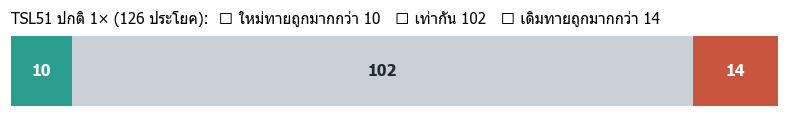

TSL51 ปกติ 1×: ใหม่ทายถูกมากกว่า 10 ประโยค · เท่ากัน 102 · เดิมทายถูกมากกว่า 14


,ผล,คำที่ทำจริง (เฉลย),เดิม (v7),ใหม่ (A 25%),ถูก (เดิม → ใหม่)
0,✅ ใหม่ดีกว่า,ฉัน ข้าว กิน,ก๋วยเตี๋ยว ✗,ฉัน ✔ ชอบ ✗ กิน ✔,0 → 2 จาก 3
1,✅ ใหม่ดีกว่า,กรุงเทพ ฉัน เที่ยว ชอบ,ฉัน ✔ หนึ่ง ✗ ชอบ ✔,กรุงเทพ ✔ ฉัน ✔ หนึ่ง ✗ ชอบ ✔,2 → 3 จาก 4
2,✅ ใหม่ดีกว่า,กรุงเทพ ฉัน เที่ยว ชอบ,ฉัน ✔ เที่ยว ✔ ชอบ ✔ ฉัน ✔,กรุงเทพ ✔ ฉัน ✔ เที่ยว ✔ ชอบ ✔ ฉัน ✔,3 → 4 จาก 4
3,❌ เดิมดีกว่า,กรุงเทพ ฉัน เที่ยว ชอบ,กรุงเทพ ✔ หนึ่ง ✗ ชอบ ✔ ฉัน ✔,กรุงเทพ ✔ หนึ่ง ✗ ฉัน ✔,3 → 2 จาก 4
4,❌ เดิมดีกว่า,กรุงเทพ ฉัน เที่ยว ชอบ,กรุงเทพ ✔ ฉัน ✔ หนึ่ง ✗ เที่ยว ✔ ชอบ ✔,กรุงเทพ ✔ วัด ✗ ฉัน ✔ หนึ่ง ✗ ชอบ ✔,4 → 3 จาก 4
5,❌ เดิมดีกว่า,กรุงเทพ แฟน เที่ยว ชอบ,ก๋วยเตี๋ยว ✗ แฟน ✔ ที่ไหน ✗ หนึ่ง ✗ ชอบ ✔,ลูก ✗ อยาก ✗ ที่ไหน ✗ หนึ่ง ✗ ชอบ ✔,2 → 1 จาก 4


In [20]:
ex_compare(LJ('cache/pitty_sent/base2_x1.0.json', 'test'), LJ('cache/pitty_sent/seq-fluent025_test_x1.0.json', 'test'), 'TSL51 ปกติ 1×', n_good=3, n_bad=3)

**สรุปจากตัวอย่าง:** tagger ใหม่ **แยกคำได้มากขึ้น** ในการทำท่าต่อเนื่อง (ของเดิมมักได้แค่ 1–2 คำจาก 4 เพราะท่าถูกรวมกัน) · บางประโยคแย่ลง (หั่นผิดที่) แต่ดีขึ้นมากกว่า · ตัวเลขละเอียดอยู่ใน G1–G4 ด้านล่าง

### G1. ส่วน tune (ใช้เลือก) — ตัวเลขทุกตัว
**อ่านตาราง (แต่ละแถว = tagger 1 ตัว):**
- `ประโยคลื่น(ง่าย)` / `ประโยคลื่น(ยาก)` = ชุดประโยคปลอมที่ทำท่าต่อเนื่อง (same = สร้างแบบเดียวกับตอนสอน · diff = ตัดเยอะกว่า เร็วกว่า)
- `… ผิด%` = WER: สัดส่วนที่ผิด (**ต่ำ = ดี**) · `… ทายถูก` = สัดส่วนคำที่ทายถูก (**สูง = ดี**) · `… ตัดได้/จริง` = ระบบแยกได้กี่คำ / จริงมีกี่คำ (**ใกล้กัน = ดี**)
- `TSL51 ปกติ / เร็ว1.5 / เร็ว2 ผิด%` = ประโยคจริง TSL51 ที่ความเร็ว 1× / 1.5× / 2× (**ห้ามแย่กว่า v7**)
- **อ่านเร็ว:** มองแถว `A 25%` เทียบแถว `v7` — ประโยคลื่นผิดน้อยลง ทายถูกเพิ่ม แยกคำได้มากขึ้น · TSL51 ใกล้เคียงเดิม

In [21]:
def LS(f, split):
    p = ROOT / f
    return {r.get('id', r.get('clip')): r for r in json.loads(p.read_text(encoding='utf-8'))['results'] if r['split'] == split} if p.exists() else None
TG = {'v7': ('v7_tune', 'base2'), 'B': ('seq-fluent0_tune', 'seq-fluent0'), 'A 50%': ('seq-fluent05_tune', 'seq-fluent05'),
      'A 25%': ('seq-fluent025_tune', 'seq-fluent025'), 'v2': ('seq-fluent025v2_tune', 'seq-fluent025v2')}
rows = []
for name, (fe, ts) in TG.items():
    F_ = LS(f'cache/fluent_eval/{fe}.json', 'tune'); r = {'tagger': name}
    for st in ('same', 'diff'):
        it = [x for x in F_.values() if x['style'] == st]
        r[f'ลื่น-{st} WER'] = np.mean([x['WER'] for x in it]); r[f'ลื่น-{st} ทายถูก'] = np.mean([x['recall1'] for x in it])
        r[f'ลื่น-{st} ตัดได้/จริง'] = f"{np.mean([x['n_pred'] for x in it]):.2f}/{np.mean([x['n_ref'] for x in it]):.2f}"
    for s in ('1.0', '1.5', '2.0'):
        r[f'TSL51 {s}x WER'] = np.mean([x['WER'] for x in LS(f'cache/pitty_sent/{ts}_x{s}.json', 'tune').values()])
    rows.append(r)
G1 = pd.DataFrame(rows).set_index('tagger')
G1.columns = [c.replace('ลื่น-same', 'ประโยคลื่น(ง่าย)').replace('ลื่น-diff', 'ประโยคลื่น(ยาก)').replace(' WER', ' ผิด%').replace('TSL51 1.0x', 'TSL51 ปกติ').replace('TSL51 1.5x', 'TSL51 เร็ว1.5').replace('TSL51 2.0x', 'TSL51 เร็ว2') for c in G1.columns]
display(G1.round(3))

,ประโยคลื่น(ง่าย) ผิด%,ประโยคลื่น(ง่าย) ทายถูก,ประโยคลื่น(ง่าย) ตัดได้/จริง,ประโยคลื่น(ยาก) ผิด%,ประโยคลื่น(ยาก) ทายถูก,ประโยคลื่น(ยาก) ตัดได้/จริง,TSL51 ปกติ ผิด%,TSL51 เร็ว1.5 ผิด%,TSL51 เร็ว2 ผิด%
tagger,,,,,,,,,
v7,0.556,0.463,3.10/3.93,0.806,0.199,1.78/4.08,0.381,0.356,0.378
B,0.528,0.481,3.15/3.93,0.794,0.210,1.78/4.08,0.384,0.376,0.374
A 50%,0.513,0.532,3.70/3.93,0.682,0.318,3.05/4.08,0.419,0.380,0.384
A 25%,0.483,0.559,3.65/3.93,0.721,0.279,2.73/4.08,0.402,0.373,0.385
v2,0.489,0.548,3.72/3.93,0.683,0.317,3.00/4.08,0.423,0.378,0.392


**TSL51 แย่ลงจริงไหม (เทียบ v7):** `ต่าง` = WER ที่เพิ่มขึ้น (บวก = แย่ลง) · **ถ้า `ci_lo` เป็นบวก = แย่ลงจริง (ตกเกณฑ์)**

In [22]:
rows = []
for name in ('B', 'A 50%', 'A 25%', 'v2'):
    for s in ('1.0', '1.5', '2.0'):
        X, V7 = LS(f'cache/pitty_sent/{TG[name][1]}_x{s}.json', 'tune'), LS(f'cache/pitty_sent/base2_x{s}.json', 'tune')
        d = np.array([X[k]['WER'] - V7[k]['WER'] for k in sorted(V7)]); m, lo, hi = boot(d)
        rows.append({'tagger': name, 'ความเร็ว': s + '×', 'ต่าง': m, 'ci_lo': lo, 'ci_hi': hi, 'ผล': '❌ แย่ลงจริง' if lo > 0 else '✅ ไม่แย่ลง'})
display(pd.DataFrame(rows).round(3))

,tagger,ความเร็ว,ต่าง,ci_lo,ci_hi,ผล
0,B,1.0×,0.003,-0.019,0.026,✅ ไม่แย่ลง
1,B,1.5×,0.020,-0.005,0.045,✅ ไม่แย่ลง
2,B,2.0×,-0.004,-0.031,0.022,✅ ไม่แย่ลง
3,A 50%,1.0×,0.038,0.010,0.065,❌ แย่ลงจริง
4,A 50%,1.5×,0.024,-0.005,0.054,✅ ไม่แย่ลง
5,A 50%,2.0×,0.006,-0.022,0.035,✅ ไม่แย่ลง
6,A 25%,1.0×,0.021,-0.003,0.046,✅ ไม่แย่ลง
7,A 25%,1.5×,0.017,-0.007,0.041,✅ ไม่แย่ลง
8,A 25%,2.0×,0.007,-0.024,0.039,✅ ไม่แย่ลง
9,v2,1.0×,0.042,0.019,0.069,❌ แย่ลงจริง


**ผลบอกอะไร (tune):**
- **B ≈ v7** → แค่สอนใหม่ไม่ได้ช่วย → ที่ดีขึ้นใน A มาจาก "ประโยคแบบลื่น" จริงๆ
- **A 50% และ v2** ช่วยประโยคลื่นมาก แต่ทำ **TSL51 1× แย่ลงจริง** → ตกเกณฑ์
- **A 25%** ช่วยประโยคลื่น และ TSL51 ไม่แย่ลงอย่างมีนัยสำคัญ → **เลือกตัวนี้**
- ทำไมยิ่งลื่นยิ่งเสีย TSL51: ประโยคปลอมที่ลื่นมากมีท่าสั้นมาก tagger เลยชินกับท่าสั้น → เจอท่าช้าๆ ก็หั่นเป็น 2 คำ

### G2. ส่วน test (เปิดครั้งเดียว หลังเลือกเสร็จ) — A 25% เทียบ v7
**อ่านตาราง:** `v7` / `A25` = ค่าของแต่ละตัว · `ต่าง` = A25 − v7 · `ci_lo` – `ci_hi` = ช่วงความเชื่อมั่น 95%
- แถว **WER**: ต่างเป็น**ลบ** และ ci ทั้งคู่ลบ = **ดีขึ้นจริง**
- แถว **recall1 (ทายถูก)**: ต่างเป็น**บวก** และ ci ทั้งคู่บวก = **ดีขึ้นจริง**
- ci คร่อม 0 = ไม่ต่าง

In [23]:
rows = []
V, A = LS('cache/fluent_eval/v7_test.json', 'test'), LS('cache/fluent_eval/seq-fluent025_test.json', 'test')
for st in ('same', 'diff'):
    k = [x for x in V if V[x]['style'] == st]
    for m_ in ('WER', 'recall1'):
        d = np.array([A[i][m_] - V[i][m_] for i in k]); m, lo, hi = boot(d)
        good = (hi < 0) if m_ == 'WER' else (lo > 0)
        rows.append({'ชุด': f'ประโยคลื่น-{st}', 'ตัววัด': m_, 'v7': np.mean([V[i][m_] for i in k]), 'A25': np.mean([A[i][m_] for i in k]), 'ต่าง': m, 'ci_lo': lo, 'ci_hi': hi,
                     'ผล': '✅ ดีขึ้นจริง' if good else '⚪ ไม่ต่าง'})
for s in ('1.0', '1.5', '2.0'):
    V7, A_ = LS(f'cache/pitty_sent/base2_x{s}.json', 'test'), LS(f'cache/pitty_sent/seq-fluent025_test_x{s}.json', 'test'); k = sorted(V7)
    d = np.array([A_[i]['WER'] - V7[i]['WER'] for i in k]); m, lo, hi = boot(d)
    rows.append({'ชุด': f'TSL51 {s}×', 'ตัววัด': 'WER', 'v7': np.mean([V7[i]['WER'] for i in k]), 'A25': np.mean([A_[i]['WER'] for i in k]), 'ต่าง': m, 'ci_lo': lo, 'ci_hi': hi,
                 'ผล': '❌ แย่ลงจริง' if lo > 0 else ('✅ ดีขึ้นจริง' if hi < 0 else '✅ ไม่แย่ลง')})
display(pd.DataFrame(rows).round(3))

,ชุด,ตัววัด,v7,A25,ต่าง,ci_lo,ci_hi,ผล
0,ประโยคลื่น-same,WER,0.528,0.504,-0.024,-0.060,0.015,⚪ ไม่ต่าง
1,ประโยคลื่น-same,recall1,0.492,0.528,0.036,0.004,0.070,✅ ดีขึ้นจริง
2,ประโยคลื่น-diff,WER,0.758,0.668,-0.089,-0.143,-0.042,✅ ดีขึ้นจริง
3,ประโยคลื่น-diff,recall1,0.246,0.344,0.098,0.049,0.152,✅ ดีขึ้นจริง
4,TSL51 1.0×,WER,0.424,0.432,0.008,-0.021,0.036,✅ ไม่แย่ลง
5,TSL51 1.5×,WER,0.380,0.374,-0.006,-0.029,0.017,✅ ไม่แย่ลง
6,TSL51 2.0×,WER,0.394,0.386,-0.008,-0.041,0.025,✅ ไม่แย่ลง


### G3. วิดีโอจริง (data_test) — A 25% เทียบ v7
**อ่านตาราง:** `เฉลย` = คำที่ทำจริง · `v7` / `A25` = คำที่แต่ละ tagger ได้ · `ถูก_…` = จำนวนคำที่ถูก

In [24]:
DT = rd('cache/analysis/data_test_tagger_compare.json')
rows = [{'วิดีโอ': v, 'เฉลย': ' '.join(x['ref']), 'v7': ' '.join(x['v7']), 'A25': ' '.join(x['A25']),
         'ถูก_v7': sum(w in x['v7'] for w in x['ref']), 'ถูก_A25': sum(w in x['A25'] for w in x['ref']), 'จำนวนคำจริง': len(x['ref'])} for v, x in DT['videos'].items()]
T_ = pd.DataFrame(rows); display(T_)
print(f"ทายถูกรวม: v7 {T_['ถูก_v7'].sum()}/{T_['จำนวนคำจริง'].sum()} · A25 {T_['ถูก_A25'].sum()}/{T_['จำนวนคำจริง'].sum()}")

,วิดีโอ,เฉลย,v7,A25,ถูก_v7,ถูก_A25,จำนวนคำจริง
0,test1,สวัสดี สบายดี ชอบ โกรธ แมว แฟน ปรบมือ,สวัสดี สบายดี ฉัน ชอบ หก แมว ข้าว แมว,สวัสดี สบายดี ชอบ หก แมว ข้าว แมว,4,4,7
1,ฉันปลอบเพื่อนร้องไห้,ฉัน ปลอบใจ เพื่อน ร้องไห้,ฉัน เพื่อน ดู สงสาร,เพื่อน ดู ข้าว สงสาร,2,1,4
2,ฉันรักเพื่อน,ฉัน รัก เพื่อน,ฉัน รัก,ฉัน รัก,2,2,3
3,พ่อดื่มน้ำ,พ่อ ดื่ม น้ำ,ศูนย์ พ่อ น้า เกิด ศูนย์,ศูนย์ พ่อ น้า ศูนย์,1,1,3
4,ไปทานข้าวด้วยกันมั้ย,ไป กิน ข้าว ด้วยกัน ไหม,คุณ ฉัน ข้าว ไป,คุณ ฉัน กิน ไป,2,2,5


ทายถูกรวม: v7 11/22 · A25 10/22


### G3b. ดูด้วยตา: tagger เดิม vs ใหม่ บนวิดีโอจริงที่ทำท่าต่อเนื่อง (3 คลิป · ดูอย่างเดียว ไม่ได้ใช้เลือกค่า)
**อ่านกราฟ:** เส้น**น้ำเงิน** = tagger เดิม (v7) · เส้น**ส้ม** = tagger ใหม่ (A 25%) → "กำลังทำท่า" แค่ไหน · **เส้นจุดเขียว** = tagger ใหม่บอกว่า "เริ่มคำใหม่" แค่ไหน
ถ้า tagger เห็นรอยต่อ: เส้นส้ม**ตกลง**ระหว่างคำ หรือเส้นเขียว**มียอด**ตรงที่คำใหม่เริ่ม

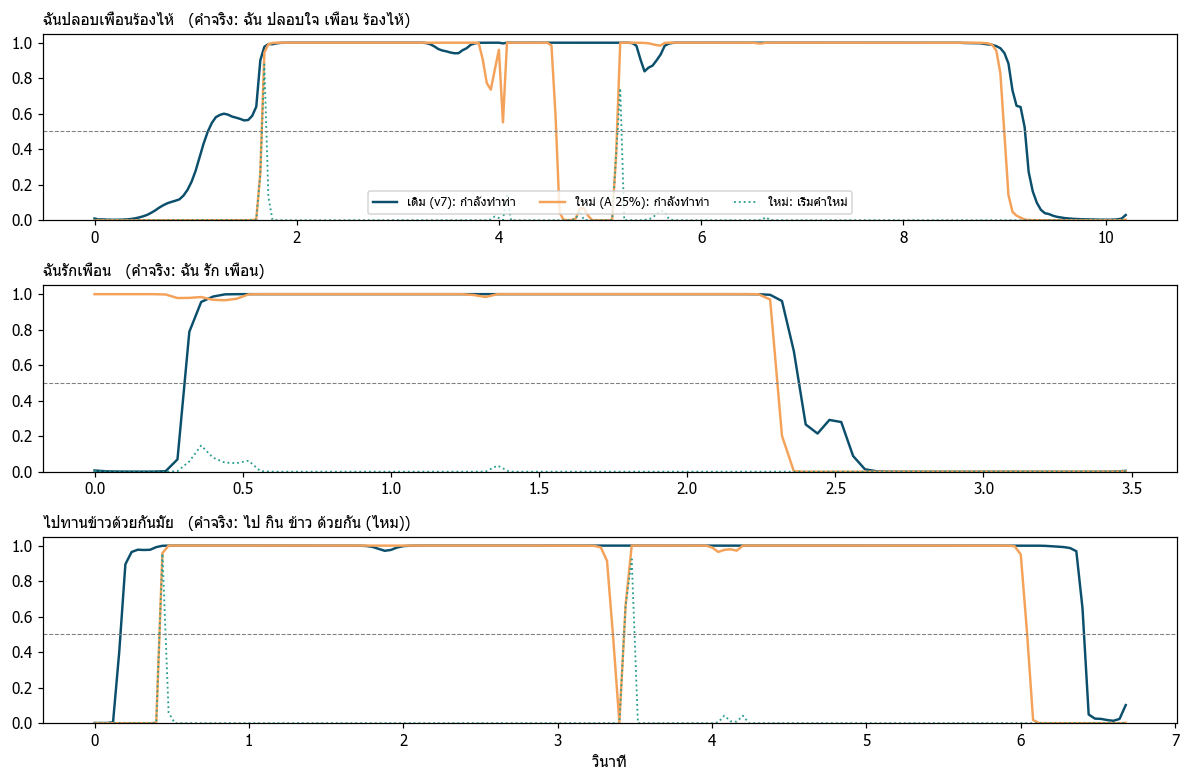

ช่วงที่แยกได้      ยอดเริ่มคำ     
tagger                                A25   v7        A25   v7
วิดีโอ               คำจริง                                   
ฉันปลอบเพื่อนร้องไห้ 4                2.0  1.0        2.0  1.0
ฉันรักเพื่อน         3                1.0  1.0        0.0  1.0
ไปทานข้าวด้วยกันมั้ย 4                2.0  1.0        2.0  1.0

In [25]:
_p2 = SignPipeline(backend='onnx', device='cpu', vocab='conversation', use_llm=False, use_face=False)
TGS = {'v7': ort.InferenceSession(str(ROOT / 'cache/backup_models_v7/tagger.onnx'), providers=['CPUExecutionProvider']),
       'A25': ort.InferenceSession(str(ROOT / 'cache/taggers/tagger_seq-fluent025.onnx'), providers=['CPUExecutionProvider'])}
REFS = {'ฉันปลอบเพื่อนร้องไห้': 'ฉัน ปลอบใจ เพื่อน ร้องไห้', 'ฉันรักเพื่อน': 'ฉัน รัก เพื่อน', 'ไปทานข้าวด้วยกันมั้ย': 'ไป กิน ข้าว ด้วยกัน (ไหม)'}
fig, axs = plt.subplots(3, 1, figsize=(11, 7.2)); rows = []
for ax, (stem, ref) in zip(axs, REFS.items()):
    kp_, sc_, hw_, pr_, _ = _p2.standardise(load_raw(ROOT / f'cache/data_test_mp/{stem}.npz')); kpi_ = to_iso(kp_, hw_)
    out = {}
    for name, sess in TGS.items():
        _p2.be.tagger = sess; prob_, _ = _p2._tag(kpi_, sc_, pr_); out[name] = prob_
        ps_ = prob_[:, 1] + prob_[:, 2]; a_ = ps_ > 0.5; b_ = np.convolve(prob_[:, 1], np.ones(3) / 3, 'same') > 0.3
        rows.append({'วิดีโอ': stem, 'คำจริง': len(ref.replace('(ไหม)', '').split()), 'tagger': name,
                     'ช่วงที่แยกได้': int((a_[1:] & ~a_[:-1]).sum() + a_[0]), 'ยอดเริ่มคำ': int((b_[1:] & ~b_[:-1]).sum() + b_[0])})
    t_ = np.arange(len(out['v7'])) / 25
    ax.plot(t_, out['v7'][:, 1] + out['v7'][:, 2], color='#0b4f6c', lw=1.6, label='เดิม (v7): กำลังทำท่า')
    ax.plot(t_, out['A25'][:, 1] + out['A25'][:, 2], color='#f4a259', lw=1.6, label='ใหม่ (A 25%): กำลังทำท่า')
    ax.plot(t_, out['A25'][:, 1], color='#2a9d8f', lw=1.2, ls=':', label='ใหม่: เริ่มคำใหม่')
    ax.axhline(0.5, color='grey', ls='--', lw=0.7); ax.set_ylim(0, 1.05); ax.set_title(f'{stem}   (คำจริง: {ref})', fontsize=10, loc='left')
axs[0].legend(fontsize=8, loc='lower center', ncol=3); axs[-1].set_xlabel('วินาที'); plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).pivot_table(index=['วิดีโอ', 'คำจริง'], columns='tagger', values=['ช่วงที่แยกได้', 'ยอดเริ่มคำ']))

**ผลบอกอะไร (ตามจริง):**
- **ปลอบเพื่อน / ไปทานข้าว:** tagger ใหม่เริ่มเห็นรอยต่อ (แยกได้ 2 ช่วงแทน 1 · มียอด "เริ่มคำใหม่" ชัดขึ้น) — **ดีขึ้นนิดหน่อย** แต่ยังไม่ครบทุกคำ
- **ฉันรักเพื่อน:** tagger ใหม่**ไม่ได้ดีขึ้น** (ยังเป็นก้อนเดียว และยอดเริ่มคำหายไปด้วย) — คลิปนี้สั้นมาก (3.5 วินาที 3 คำ ทำเร็ว)
- **สรุป:** บนวิดีโอธรรมชาติ tagger ใหม่**ช่วยได้บ้างแต่ยังห่างจากที่ควรเป็น** — สอดคล้องกับผลทายคำที่เท่าเดิม (G3) · ประโยคปลอมที่ใช้สอนยัง "ลื่นไม่เท่าของจริง" (ส่วน F) → ต้องมีวิดีโอทำท่าต่อเนื่องจริงมาใช้สอน / วัดผล

### G4. ท่าของคนจริงที่ทำให้ลื่นขึ้น — TSL51 test `no_space` ตัดช่วงมือค้างระหว่างคำ (ดู C2)
ประโยคลื่นใน G1–G2 เป็นประโยคปลอม → ทดสอบเพิ่มกับ**ท่าของคนจริง** (114 ประโยคที่ tagger ไม่เคยเรียน) ที่ตัดช่วงมือค้างนิ่งออก · การตั้งค่าการตัดเลือกด้วย tagger v7 เท่านั้น
**อ่านตาราง:** `WER` ต่ำ = ดี · `ทายถูก` สูง = ดี · `คำหาย` = สัดส่วนคำที่ระบบไม่ได้ตัดออกมา · `ตัดได้/จริง` = ระบบตัดได้กี่คำ / จริงกี่คำ

In [26]:
def LC(n): return {r['clip']: r for r in json.loads((ROOT / f'cache/pitty_sent/{n}.json').read_text(encoding='utf-8'))['results']}
HCR = {'v7': LC('holdcut_v7_test'), 'B': LC('holdcut_B_test'), 'A 25%': LC('holdcut_A25_test')}; k = sorted(HCR['v7'])
rows = []
for name, X in HCR.items():
    S = Dl = I = N = 0
    for i in k:
        s_, d_, i_ = edits(X[i]['ref'], X[i]['top1']); S += s_; Dl += d_; I += i_; N += len(X[i]['ref'])
    rows.append({'tagger': name, 'WER': np.mean([X[i]['WER'] for i in k]), 'ทายถูก': np.mean([X[i]['recall1'] for i in k]), 'คำหาย': Dl / N,
                 'ตัดได้/จริง': f"{np.mean([X[i]['n_pred'] for i in k]):.2f}/{np.mean([X[i]['n_ref'] for i in k]):.2f}"})
display(pd.DataFrame(rows).set_index('tagger').round(3))
rows = []
for a_, b_ in (('A 25%', 'v7'), ('A 25%', 'B'), ('B', 'v7')):
    for m_ in ('WER', 'recall1'):
        d = np.array([HCR[a_][i][m_] - HCR[b_][i][m_] for i in k]); m, lo, hi = boot(d)
        good = (hi < 0) if m_ == 'WER' else (lo > 0)
        rows.append({'เทียบ': f'{a_} − {b_}', 'ตัววัด': m_, 'ต่าง': m, 'ci_lo': lo, 'ci_hi': hi, 'ผล': '✅ ดีขึ้นจริง' if good else '⚪ ไม่ต่าง'})
display(pd.DataFrame(rows).round(3))

,WER,ทายถูก,คำหาย,ตัดได้/จริง
tagger,,,,
v7,0.630,0.377,0.365,2.29/3.58
B,0.614,0.390,0.358,2.31/3.58
A 25%,0.581,0.423,0.331,2.40/3.58


,เทียบ,ตัววัด,ต่าง,ci_lo,ci_hi,ผล
0,A 25% − v7,WER,-0.049,-0.086,-0.013,✅ ดีขึ้นจริง
1,A 25% − v7,recall1,0.046,0.010,0.083,✅ ดีขึ้นจริง
2,A 25% − B,WER,-0.033,-0.070,0.002,⚪ ไม่ต่าง
3,A 25% − B,recall1,0.033,-0.001,0.070,⚪ ไม่ต่าง
4,B − v7,WER,-0.016,-0.047,0.014,⚪ ไม่ต่าง
5,B − v7,recall1,0.013,-0.015,0.043,⚪ ไม่ต่าง


**ผลบอกอะไร:** บนท่าของคนจริง A 25% **ดีกว่า v7 อย่างมีนัยสำคัญ** (WER −0.049, ทายถูก +0.046) และตัวควบคุม B ไม่ต่างจาก v7 → หลักฐานชิ้นแรกที่ไม่ได้มาจากประโยคปลอม · ข้อจำกัด: ยังลื่นไม่เท่าการทำท่าธรรมชาติ

## สรุปผลสุดท้าย
| คำถาม | คำตอบ |
|---|---|
| tagger ใหม่ (A 25%) แยกคำในการทำท่า**ต่อเนื่อง**ได้ดีขึ้นไหม | ✅ **ดีขึ้นจริง** (ประโยคลื่น-diff: ทายถูก 25% → 34%, แยกคำได้ 1.97 → 2.85 จาก 4.08 คำ) |
| ทำให้ประโยคแบบ**หยุดพัก** (TSL51) แย่ลงไหม | ✅ **ไม่แย่ลง** ทุกความเร็ว |
| กับ**ท่าของคนจริง**ที่ทำให้ลื่นขึ้น (TSL51 ตัดช่วงค้าง) | ✅ **ดีขึ้นจริง** (WER 0.630 → 0.581, ทายถูก 0.377 → 0.423) |
| กับ**วิดีโอจริง** (data_test) ดีขึ้นไหม | ⚪ **ยังบอกไม่ได้** — 10 vs 11 จาก 22 คำ (ต่าง 1 คำ) · 5 คลิปน้อยเกินไป |
| ตอนนี้ระบบในเครื่องใช้ตัวไหน | **A 25%** (`models/onnx/tagger.onnx`) · ตัวเดิมสำรองที่ `cache/backup_models_v7/` |
| ต่อไปควรทำอะไร | **อัดวิดีโอประโยคที่ทำท่าต่อเนื่องจริง 30–50 ประโยค** ไว้วัดผล |

**ข้อควรระวัง:** ประโยคลื่นที่ใช้วัด สร้างด้วยวิธีคล้ายตอนสอน A → อาจเข้าข้าง A อยู่บ้าง · ตัวตัดสินที่เป็นอิสระคือ TSL51 (ผ่าน) และวิดีโอจริง (เท่าเดิม) · data_test ถูกดูเกินที่ตั้งใจ 1 รอบ (รอบ A 50% โดยไม่ตั้งใจ)

---
## H. ผลอื่นที่ใช้อยู่ในระบบ + โหมดกล้องสด (เว็บเดโม)

### H1. ตัวตัดคำ `min_frames` 14 → 10 (รอบก่อน ข้อ 9b)
**คืออะไร:** ท่าที่สั้นกว่า X เฟรม ถูกทิ้ง (ถือว่าไม่ใช่คำ) · 14 เฟรม = 0.56 วินาที → 10 เฟรม = 0.4 วินาที · ตอนทำท่าเร็ว ท่าจริงสั้นลงจนโดนทิ้ง คำเลยหาย
**อ่านตาราง:** TSL51 ครึ่ง test · ตัวเลข = WER (% ที่ผิด ต่ำ = ดี) · `ต่าง` = ใหม่ − เดิม · `ci_lo`–`ci_hi` = ช่วงความเชื่อมั่น 95%

In [27]:
rows = []
for s_, a_ in (('1.0', 'a0_x1'), ('1.5', 'a0_x1.5'), ('2.0', 'a0_x2.0')):
    A_ = {r['clip']: r['WER'] for r in json.loads((ROOT / f'cache/pitty_sent/{a_}.json').read_text(encoding='utf-8'))['results'] if r['split'] == 'test'}
    B_ = {r['clip']: r['WER'] for r in json.loads((ROOT / f'cache/pitty_sent/c_L14F10_x{s_}.json').read_text(encoding='utf-8'))['results'] if r['split'] == 'test'}
    k = sorted(A_); d = np.array([B_[i] - A_[i] for i in k]); m, lo, hi = boot(d)
    rows.append({'ความเร็ว': s_ + '×', 'min_frames 14 (เดิม)': np.mean([A_[i] for i in k]), 'min_frames 10 (ใหม่)': np.mean([B_[i] for i in k]),
                 'ต่าง': m, 'ci_lo': lo, 'ci_hi': hi, 'ผล': '✅ ดีขึ้นจริง' if hi < 0 else ('❌ แย่ลง' if lo > 0 else '⚪ ไม่ต่าง')})
display(pd.DataFrame(rows).round(3))

,ความเร็ว,min_frames 14 (เดิม),min_frames 10 (ใหม่),ต่าง,ci_lo,ci_hi,ผล
0,1.0×,0.424,0.424,0.000,0.000,0.000,⚪ ไม่ต่าง
1,1.5×,0.380,0.380,0.000,0.000,0.000,⚪ ไม่ต่าง
2,2.0×,0.406,0.394,-0.013,-0.026,-0.002,✅ ดีขึ้นจริง


**ตัวอย่างจริง** (ทำท่าเร็ว 2× · ครึ่ง test): min_frames 10 เก็บท่าสั้นไว้ได้ → คำที่เคยหายกลับมา

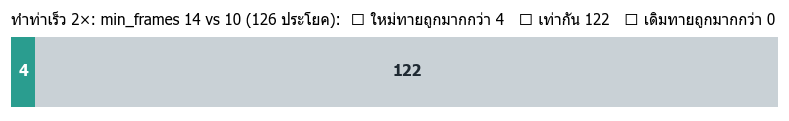

ทำท่าเร็ว 2×: min_frames 14 vs 10: ใหม่ทายถูกมากกว่า 4 ประโยค · เท่ากัน 122 · เดิมทายถูกมากกว่า 0


,ผล,คำที่ทำจริง (เฉลย),min_frames 14 (เดิม),min_frames 10 (ใหม่),ถูก (เดิม → ใหม่)
0,✅ ใหม่ดีกว่า,น้อง เกิด หูหนวก,ฉัน ✗ หูหนวก ✔,น้อง ✔ เกิด ✔ หูหนวก ✔,1 → 3 จาก 3
1,✅ ใหม่ดีกว่า,กรุงเทพ แฟน เที่ยว ชอบ,หนึ่ง ✗ ชอบ ✔,แฟน ✔ หนึ่ง ✗ ชอบ ✔,1 → 2 จาก 4
2,✅ ใหม่ดีกว่า,ขนมปัง คุณ กิน,ขนมปัง ✔ ต้อง ✗,ขนมปัง ✔ คุณ ✔ เค็ม ✗,1 → 2 จาก 3
3,✅ ใหม่ดีกว่า,ฉัน ข้าว กิน,ฉัน ✔,ฉัน ✔ กิน ✔,1 → 2 จาก 3


In [28]:
ex_compare(LJ('cache/pitty_sent/a0_x2.0.json', 'test'), LJ('cache/pitty_sent/c_L14F10_x2.0.json', 'test'), 'ทำท่าเร็ว 2×: min_frames 14 vs 10',
           old_name='min_frames 14 (เดิม)', new_name='min_frames 10 (ใหม่)', n_good=4, n_bad=2)

**ผลบอกอะไร:** ทำท่าเร็ว (2×) **ผิดน้อยลงจริง** (0.406 → 0.394) · ความเร็วอื่นเท่าเดิม → ใช้อยู่ใน `models/spotting.json`

### H2. โหมดกล้องสด — ลองจริงในเว็บเดโม
ทุกครั้งที่ทำท่าในเว็บ ระบบเก็บจุดบนร่างกาย + ผลไว้ที่ `cache/live_requests/` (ไม่มีวิดีโอ)

**อ่านตาราง:**
- `ความละเอียด` = ขนาดภาพกล้อง (1280x720 = ปกติ · 848x480 = แบบเบา `?cam=480`)
- `fps` = ภาพต่อวินาทีที่จับได้จริง (โมเดลถูกสอนที่ 25)
- `มือหายตอนยก` = สัดส่วนเฟรมที่ข้อมือยกสูงกว่าอก แต่ระบบหามือไม่เจอ (วิดีโอทดสอบ ≈ 9%)
- `คำแรกที่ระบบได้` / `มั่นใจ` = คำของช่วงแรก และความมั่นใจ (0–1)
- `พูดออกมา` = คำที่มั่นใจ ≥ 0.8 (ต่ำกว่านั้นไม่พูด — ตั้งใจออกแบบไว้ "ไม่มั่นใจ 80% อย่าเดา")

In [29]:
import gzip, glob, os
LR = []
for f in sorted(glob.glob(str(ROOT / 'cache/live_requests/*.json.gz')), key=os.path.getmtime):
    d = json.load(gzip.open(f)); fr = d['frames']; r = d['result']; dur = r.get('duration_s') or 1
    raised = miss = 0
    for x in fr:
        p_ = x['pose']
        if len(p_) < 25: continue
        p_ = np.array(p_); sh = (p_[11][1] + p_[12][1]) / 2; hip = (p_[23][1] + p_[24][1]) / 2
        for wi, key in ((15, 'lh'), (16, 'rh')):
            if p_[wi][1] < sh + 0.6 * (hip - sh) and (p_.shape[1] < 4 or p_[wi][3] > 0.5):
                raised += 1; miss += len(x[key]) == 0
    segs = [x for x in r.get('segments', []) if isinstance(x, dict) and x.get('status') != 'transition']
    LR.append({'เวลา': d['time'], 'ความละเอียด': f"{d['width']}x{d['height']}", 'วินาที': dur, 'fps': len(fr) / dur,
               'มือหายตอนยก': miss / max(raised, 1), 'คำแรกที่ระบบได้': segs[0].get('word') if segs else '',
               'มั่นใจ': segs[0].get('p') if segs else np.nan, 'พูดออกมา': r.get('sentence') or '—'})
LR = pd.DataFrame(LR)
today = LR[LR['เวลา'] >= '2026-10-11 09:12'].reset_index(drop=True)
display(today.round(2))
print(f"ทุกครั้งที่ลอง ({len(LR)} ครั้ง): fps ค่ากลาง {LR.fps.median():.1f} · มือหายตอนยก เฉลี่ย {LR['มือหายตอนยก'].mean():.0%} (วิดีโอทดสอบ ≈ 9%)")

,เวลา,ความละเอียด,วินาที,fps,มือหายตอนยก,คำแรกที่ระบบได้,มั่นใจ,พูดออกมา
0,2026-10-11 09:12:12,1280x720,1.84,9.24,0.45,สวัสดี,0.86,สวัสดี
1,2026-10-11 09:12:12,1280x720,2.20,11.82,0.43,จีน,0.11,—
2,2026-10-11 09:12:30,1280x720,7.52,12.50,0.17,ภาพ,0.14,—
3,2026-10-11 09:12:49,1280x720,3.00,10.33,0.43,พี่,0.08,—
4,2026-10-11 09:12:51,1280x720,3.20,7.50,0.05,ใช่,0.46,—
5,2026-10-11 09:13:07,1280x720,5.80,13.10,0.39,ประเทศไทย,0.09,—
6,2026-10-11 09:13:19,1280x720,1.76,13.07,0.24,ปวดหัว,0.18,—
7,2026-10-11 09:14:20,848x480,4.28,12.38,0.15,แมว,0.14,สวัสดี
8,2026-10-11 09:14:36,848x480,2.12,14.62,0.17,สวัสดี,0.92,สวัสดี
9,2026-10-11 09:15:07,848x480,2.80,15.71,0.11,แมว,0.02,—


ทุกครั้งที่ลอง (41 ครั้ง): fps ค่ากลาง 10.3 · มือหายตอนยก เฉลี่ย 29% (วิดีโอทดสอบ ≈ 9%)


**แบบปกติ vs แบบเบา** — ช่วงที่ลองทำ "สวัสดี" (09:12–09:16 · ผู้ใช้ทำท่าเดียว)
`ได้สวัสดี` = จำนวนครั้งที่ระบบพูด "สวัสดี" ออกมา (มั่นใจ ≥ 0.8)

In [30]:
hi_ = today[today['เวลา'] < '2026-10-11 09:16:30'].copy()
hi_['แบบ'] = hi_['ความละเอียด'].map(lambda x: 'แบบเบา 848x480' if x.startswith('848') else 'ปกติ 1280x720')
g = hi_.groupby('แบบ')
display(pd.DataFrame({'ครั้ง': g.size(), 'fps เฉลี่ย': g.fps.mean(), 'มือหายตอนยก': g['มือหายตอนยก'].mean(),
                      'ได้สวัสดี': g['พูดออกมา'].apply(lambda x: int((x == 'สวัสดี').sum()))}).round(2))

,ครั้ง,fps เฉลี่ย,มือหายตอนยก,ได้สวัสดี
แบบ,,,,
ปกติ 1280x720,9,11.88,0.33,2
แบบเบา 848x480,4,15.00,0.20,3


**ผลบอกอะไร:**
- **ตัวการหลักในโหมดสด = มือหาย** (หลายครั้ง 30–90% ตอนยกมือ เทียบวิดีโอทดสอบ ~9%) → แก้ที่แสง ระยะ ฉากหลัง
- **แบบเบา (`?cam=480`) ได้ fps สูงกว่า มือหายน้อยกว่า และพูด "สวัสดี" ออกมาบ่อยกว่า** — แต่ลองไม่กี่ครั้ง
- **"สบายดี"** (09:17): ระบบได้ สบายดี เป็นอันดับ 1 บ้าง แต่มั่นใจแค่ 0.55–0.68 เพราะสับสนกับ "มีความสุข" / "สบาย" (มีตัวอย่างใน bank แค่ 1 คลิป) → ไม่ถึง 0.8 เลยไม่พูด

### H3. fps ต่ำ ทำให้แย่แค่ไหน (จำลองบน TSL51 ครึ่ง tune · tagger ใหม่)
**ทำยังไง:** เอาประโยค TSL51 (25 fps) มาสุ่มเก็บภาพแค่ 15 / 9 / 6 ภาพต่อวินาที แล้วยืดกลับเป็น 25 แบบเดียวกับที่เว็บทำ
**อ่านตาราง:** `error รวม` = (ผิด + หาย + เกิน) ÷ คำจริง (ต่ำ = ดี)

In [31]:
rows = []
for lab, f in (('25 fps (ปกติ)', 'seq-fluent025_x1.0'), ('15 fps', 'fps15_A25_x1.0'), ('9 fps (≈ โหมดสด)', 'fps9_A25_x1.0'), ('6 fps', 'fps6_A25_x1.0'),
               ('25 fps · ทำท่าเร็ว 2×', 'seq-fluent025_x2.0'), ('9 fps · ทำท่าเร็ว 2×', 'fps9_A25_x2.0')):
    x = load(f)
    if x: rows.append({'แบบ': lab, **er(x)})
display(pd.DataFrame(rows).set_index('แบบ').round(3))

,error รวม,ทายผิดคำ,คำหาย,คำเกิน
แบบ,,,,
25 fps (ปกติ),0.415,0.367,0.029,0.019
15 fps,0.415,0.369,0.029,0.017
9 fps (≈ โหมดสด),0.410,0.362,0.029,0.019
6 fps,0.415,0.365,0.036,0.014
25 fps · ทำท่าเร็ว 2×,0.391,0.271,0.118,0.002
9 fps · ทำท่าเร็ว 2×,0.408,0.302,0.103,0.002


**ผลบอกอะไร:** ทำท่าความเร็วปกติ **fps ต่ำแทบไม่มีผล** (6–25 fps ได้เท่ากัน) · ทำท่าเร็วแย่ลงนิดหน่อย → **fps ไม่ใช่ตัวการหลักของโหมดสด**

---
## I. สรุปผลทั้งหมด (อ่านง่าย)
`ผิด %` = WER (ยิ่งต่ำยิ่งดี) · ทุกบรรทัดคำนวณจากไฟล์ใน `cache/` (ส่วน G, H)

In [32]:
def mean_wer(f, split):
    return np.mean([r['WER'] for r in json.loads((ROOT / f'cache/{f}.json').read_text(encoding='utf-8'))['results'] if r['split'] == split])
fv7, fa = LS('cache/fluent_eval/v7_test.json', 'test'), LS('cache/fluent_eval/seq-fluent025_test.json', 'test')
kd = [x for x in fv7 if fv7[x]['style'] == 'diff']
S_ = [
    ['tagger ใหม่', 'ประโยคลื่น (ประโยคปลอมที่ทำท่าต่อเนื่อง)', np.mean([fv7[i]['WER'] for i in kd]), np.mean([fa[i]['WER'] for i in kd]), '✅ ผิดน้อยลง'],
    ['tagger ใหม่', 'ท่าคนจริง (TSL51 ตัดช่วงค้าง)', mean_wer('pitty_sent/holdcut_v7_test', 'test'), mean_wer('pitty_sent/holdcut_A25_test', 'test'), '✅ ผิดน้อยลง'],
    ['tagger ใหม่', 'TSL51 ปกติ 1× (คนทำช้า ค้างมือ)', mean_wer('pitty_sent/base2_x1.0', 'test'), mean_wer('pitty_sent/seq-fluent025_test_x1.0', 'test'), '✅ เท่าเดิม (ไม่พัง)'],
    ['tagger ใหม่', 'TSL51 ปกติ 2× (ทำเร็ว)', mean_wer('pitty_sent/base2_x2.0', 'test'), mean_wer('pitty_sent/seq-fluent025_test_x2.0', 'test'), '✅ เท่าเดิม (ไม่พัง)'],
    ['min_frames 14 → 10', 'TSL51 2× (ทำเร็ว)', mean_wer('pitty_sent/a0_x2.0', 'test'), mean_wer('pitty_sent/c_L14F10_x2.0', 'test'), '✅ ผิดน้อยลง'],
]
T_ = pd.DataFrame(S_, columns=['สิ่งที่แก้', 'ทดสอบกับ (ครึ่ง test)', 'เดิม ผิด %', 'ใหม่ ผิด %', 'แปลว่า'])
for c_ in ('เดิม ผิด %', 'ใหม่ ผิด %'):
    T_[c_] = (T_[c_] * 100).round(1).astype(str) + '%'
display(T_)

,สิ่งที่แก้,ทดสอบกับ (ครึ่ง test),เดิม ผิด %,ใหม่ ผิด %,แปลว่า
0,tagger ใหม่,ประโยคลื่น (ประโยคปลอมที่ทำท่าต่อเนื่อง),75.8%,66.8%,✅ ผิดน้อยลง
1,tagger ใหม่,ท่าคนจริง (TSL51 ตัดช่วงค้าง),63.0%,58.1%,✅ ผิดน้อยลง
2,tagger ใหม่,TSL51 ปกติ 1× (คนทำช้า ค้างมือ),42.4%,43.2%,✅ เท่าเดิม (ไม่พัง)
3,tagger ใหม่,TSL51 ปกติ 2× (ทำเร็ว),39.4%,38.6%,✅ เท่าเดิม (ไม่พัง)
4,min_frames 14 → 10,TSL51 2× (ทำเร็ว),40.6%,39.4%,✅ ผิดน้อยลง


**ตัวเลขเดียวกันแบบ "นับคำดิบๆ"** (ไม่ใช้ % — นับคำจริงทุกคำในชุดทดสอบ)
- `คำทั้งหมด` = จำนวนคำในเฉลยรวมทุกประโยค · `ถูก` = คำที่ได้ถูกตรงตำแหน่ง
- `ผิดคำ` = ได้คำแต่เป็นคำอื่น · `หาย` = คำที่ระบบไม่ได้ออกมา · `เกิน` = คำที่ระบบได้ แต่ไม่มีอยู่จริง
- **ถูก + ผิดคำ + หาย = คำทั้งหมด** · ผิด % (แบบรวม) = (ผิดคำ + หาย + เกิน) ÷ คำทั้งหมด

In [33]:
def raw_counts(rows):
    N = S = D = I = 0
    for r in rows:
        s_, d_, i_ = edits(r['ref'], r['top1']); S += s_; D += d_; I += i_; N += len(r['ref'])
    return N, N - S - D, S, D, I
pairs = [('tagger ใหม่ · ประโยคลื่น', LJ('cache/fluent_eval/v7_test.json', 'test', 'diff'), LJ('cache/fluent_eval/seq-fluent025_test.json', 'test', 'diff')),
         ('tagger ใหม่ · ท่าคนจริง (ตัดช่วงค้าง)', LJ('cache/pitty_sent/holdcut_v7_test.json', 'test'), LJ('cache/pitty_sent/holdcut_A25_test.json', 'test')),
         ('tagger ใหม่ · TSL51 ปกติ 1×', LJ('cache/pitty_sent/base2_x1.0.json', 'test'), LJ('cache/pitty_sent/seq-fluent025_test_x1.0.json', 'test')),
         ('tagger ใหม่ · TSL51 2×', LJ('cache/pitty_sent/base2_x2.0.json', 'test'), LJ('cache/pitty_sent/seq-fluent025_test_x2.0.json', 'test')),
         ('min_frames 10 · TSL51 2×', LJ('cache/pitty_sent/a0_x2.0.json', 'test'), LJ('cache/pitty_sent/c_L14F10_x2.0.json', 'test'))]
rows = []
for name, a_, b_ in pairs:
    N, oa, sa, da, ia = raw_counts(a_.values()); _, ob, sb, db, ib = raw_counts(b_.values())
    rows.append({'ทดสอบ': name, 'ประโยค': len(a_), 'คำทั้งหมด': N, 'ถูก (เดิม→ใหม่)': f'{oa} → {ob}', 'ผิดคำ': f'{sa} → {sb}', 'หาย': f'{da} → {db}', 'เกิน': f'{ia} → {ib}'})
display(pd.DataFrame(rows).set_index('ทดสอบ'))

,ประโยค,คำทั้งหมด,ถูก (เดิม→ใหม่),ผิดคำ,หาย,เกิน
ทดสอบ,,,,,,
tagger ใหม่ · ประโยคลื่น,60,245,59 → 82,59 → 88,127 → 75,0 → 1
tagger ใหม่ · ท่าคนจริง (ตัดช่วงค้าง),114,408,153 → 170,106 → 103,149 → 135,2 → 1
tagger ใหม่ · TSL51 ปกติ 1×,126,450,287 → 287,141 → 149,22 → 14,36 → 39
tagger ใหม่ · TSL51 2×,126,450,272 → 277,97 → 108,81 → 65,4 → 5
min_frames 10 · TSL51 2×,126,450,267 → 272,93 → 97,90 → 81,4 → 4


**อ่านยังไง:** เช่น ท่าคนจริง 408 คำ — ของเดิมได้ถูก 153 คำ ของใหม่ 170 คำ (**+17 คำ**) ส่วนใหญ่มาจาก**คำหายน้อยลง** (149 → 135) = ของใหม่แยกท่าที่ติดกันออกมาเป็นคำได้มากขึ้น
- ประโยคลื่น: ถูก 59 → 82 (+23) · หาย 127 → 75 (ของเดิมรวมท่าจนคำหายเกินครึ่ง)
- TSL51 ปกติ 1×: ถูก 287 → 287 (เท่ากันเป๊ะ) · TSL51 2×: 272 → 277 · min_frames 10: 267 → 272 (หาย 90 → 81)

| สิ่งที่แก้ / พบ | ผล | ดูที่ |
|---|---|---|
| ปิด "ปรับแสงอัตโนมัติ" | มือหาย 19.8% → 8.9% (วิดีโอทดสอบ) | `pitty_phase1_hands.ipynb` |
| กล้องแบบเบา `?cam=480` | fps สูงขึ้น มือหายน้อยลง พูด "สวัสดี" บ่อยขึ้น (ลองน้อย) | H2 |
| โหมดสด: ตัวการหลัก | มือหายตอนยก (หลายครั้ง 30–90%) · fps ต่ำแทบไม่มีผล | H2, H3 |
| เกณฑ์ 80% | คำที่มั่นใจไม่ถึง 0.8 ไม่พูด (ตั้งใจออกแบบ) · สบายดี ได้ 0.55–0.68 | H2 |
| วิดีโอจริง 5 คลิป (data_test) | tagger ใหม่ 10 vs เดิม 11 จาก 22 คำ = เท่าเดิม (คลิปน้อยเกินจะตัดสิน) | G3 |
| ลองแล้วไม่ได้ผล | augmentation 4 แบบ · train encoder ใหม่ · ปรับ lam · ประโยคลื่นกว่านี้ (v2) | D, G1, phase5 |

**ขั้นต่อไป:** (1) อัดวิดีโอประโยคที่ทำท่าต่อเนื่องจริง 30–50 ประโยคไว้วัดผล (2) แก้การจับมือในโหมดสด (แสง ระยะ ฉากหลัง + กล้องแบบเบา) (3) เพิ่มคนทำท่าต่อคำ (4) ใช้ปุ่ม "ยืนยันคำ" สอนท่าของผู้ใช้ (5) เรียบเรียงประโยคไว้ทำตอนท้าย